# Mechanism Analysis of PatchCore under Training-Set Contamination

## Research Objective

This notebook investigates **how training-set contamination propagates through the PatchCore normality model**.

The analysis focuses on the causal chain:

**Training contamination**
↓  
**Memory-bank composition**
↓  
**Nearest-neighbour retrieval**
↓  
**Anomaly distance / score**
↓  
**Detection ranking**

The clean and 20% contaminated PatchCore models are analysed using the **same fixed test set and baseline configuration**.

### Important distinction

We separately investigate:

**A. Memory inclusion:**  
Whether contaminated training-image features are actually selected into the PatchCore memory bank.

**B. Retrieval restructuring:**  
Whether the presence of contaminated training data changes which memory vectors become nearest neighbours, even when the test-image feature representation itself remains unchanged.

No new model is trained in this notebook.


## 1. Environment and Experimental Paths

### Purpose

Load the required libraries and define the locations of the already completed PatchCore models.

The clean and contaminated models will be **loaded**, not retrained.

** Restore the PatchCore environment**

In [1]:
%cd /content

!git clone -q https://github.com/amazon-science/patchcore-inspection.git /content/patchcore-inspection 2>/dev/null || true

%cd /content/patchcore-inspection

!pip install -q -r requirements.txt
!pip install -q -e .
%pip install -q faiss-cpu

print("PatchCore environment setup completed.")

/content
/content/patchcore-inspection
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for patchcore (pyproject.toml) ... done
PatchCore environment setup completed.


In [2]:
import os
import sys
import numpy as np
import torch
import faiss

# Add PatchCore source directory to Python path to prevent ModuleNotFoundError
sys.path.append('/content/patchcore-inspection/src')

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("FAISS:", faiss.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU: Not available")

from patchcore.patchcore import PatchCore
from patchcore.common import FaissNN

print("PatchCore import: SUCCESS")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
FAISS: 1.15.1
GPU available: True
GPU: Tesla T4
PatchCore import: SUCCESS


## 2. Locate Saved PatchCore Models

We compare the already completed:
- 0% clean PatchCore model
- 20% contaminated PatchCore model

No retraining is performed.

# Mount Google Drive



In [3]:
from google.colab import drive

drive.mount("/content/drive")

print("Google Drive mounted successfully.")

Mounted at /content/drive
Google Drive mounted successfully.


In [4]:
import os

PROJECT_ROOT = "/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT"

CLEAN_MODEL = os.path.join(
    PROJECT_ROOT,
    "Experiments/PatchCore/bottle/PatchCore/clean_baseline/models/mvtec_bottle"
)

CONTAM_MODEL = os.path.join(
    PROJECT_ROOT,
    "Experiments/PatchCore/bottle/PatchCore/20_percent/models/mvtec_bottle"
)

print("Clean model exists:", os.path.exists(CLEAN_MODEL))
print("20% model exists:", os.path.exists(CONTAM_MODEL))

print("\nClean:", CLEAN_MODEL)
print("20%:", CONTAM_MODEL)

Clean model exists: True
20% model exists: False

Clean: /content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/PatchCore/clean_baseline/models/mvtec_bottle
20%: /content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/PatchCore/20_percent/models/mvtec_bottle


In [5]:
import os

EXP_ROOT = os.path.join(
    PROJECT_ROOT,
    "Experiments",
    "PatchCore",
    "bottle",
    "PatchCore"
)

print("PatchCore experiment folder exists:", os.path.exists(EXP_ROOT))
print("\nContents:\n")

for root, dirs, files in os.walk(EXP_ROOT):
    level = root.replace(EXP_ROOT, "").count(os.sep)
    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")
        for f in files[:10]:
            print("  " * (level + 1) + f)

PatchCore experiment folder exists: True

Contents:

PatchCore/
  clean_baseline/
    results.csv
    models/
      mvtec_bottle/
        nnscorer_search_index.faiss
        patchcore_params.pkl
  clean_baseline_0/
    results.csv
    experiment_config.json
    command.txt
    models/
      mvtec_bottle/
        nnscorer_search_index.faiss
        patchcore_params.pkl
  clean_baseline_1/
    results.csv
    models/
      mvtec_bottle/
        nnscorer_search_index.faiss
        patchcore_params.pkl


In [6]:
# Find the actual 20% experiment folder

SEARCH_ROOT = os.path.join(
    PROJECT_ROOT,
    "Experiments"
)

for root, dirs, files in os.walk(SEARCH_ROOT):
    for d in dirs:
        if "20" in d.lower() and "percent" in d.lower():
            print(os.path.join(root, d))

/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/20_percent


In [7]:
# Correct saved-model paths

CLEAN_MODEL = os.path.join(
    PROJECT_ROOT,
    "Experiments/PatchCore/bottle/PatchCore/"
    "clean_baseline/models/mvtec_bottle"
)

CONTAM_MODEL = os.path.join(
    PROJECT_ROOT,
    "Experiments/PatchCore/bottle/20_percent/"
    "models/mvtec_bottle"
)

print("Clean model exists:", os.path.exists(CLEAN_MODEL))
print("20% model exists:", os.path.exists(CONTAM_MODEL))

Clean model exists: True
20% model exists: True


## 3. Load the Existing PatchCore Models

### Purpose
Load the previously completed clean and 20% contaminated PatchCore models.

No retraining is performed. We only load the saved models for mechanism analysis.

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def load_patchcore(model_path):
    model = PatchCore(device)
    nn_method = FaissNN(on_gpu=False, num_workers=4)
    # Creates the FAISS nearest-neighbour search system that PatchCore uses to find similar feature vectors.

    model.load_from_path(
        load_path=model_path,
        device=device,
        nn_method=nn_method
    )

    return model


clean_model = load_patchcore(CLEAN_MODEL)
contam_model = load_patchcore(CONTAM_MODEL)

print("Clean PatchCore model: loaded")
print("20% contaminated PatchCore model: loaded")

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=Wide_ResNet50_2_Weights.IMAGENET1K_V1`. You can also use `weights=Wide_ResNet50_2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/wide_resnet50_2-95faca4d.pth" to /root/.cache/torch/hub/checkpoints/wide_resnet50_2-95faca4d.pth


100%|██████████| 132M/132M [00:00<00:00, 199MB/s]


Clean PatchCore model: loaded
20% contaminated PatchCore model: loaded


pretrained is deprecated → just a torchvision API warning.
The 132 MB download → ImageNet WideResNet50 pretrained weights were downloaded because this fresh Colab runtime didn't have them cached.
Most important:
Clean PatchCore model: loaded
20% contaminated PatchCore model: loaded

Next, we need to see what is actually stored inside PatchCore's nearest-neighbour system.

We don't assume how your installed PatchCore version stores the memory bank.

First we inspect it → then we decide exactly how to extract:

memory bank → feature vectors → training-image provenance → contaminated vs clean

In [9]:
# Inspect the nearest-neighbour objects

clean_nn = clean_model.anomaly_scorer.nn_method
contam_nn = contam_model.anomaly_scorer.nn_method

print("Clean NN object:", type(clean_nn))
print("20% contaminated NN object:", type(contam_nn))

print("\nClean NN attributes:")
print([x for x in dir(clean_nn) if not x.startswith("_")])

print("\n20% contaminated NN attributes:")
print([x for x in dir(contam_nn) if not x.startswith("_")])

Clean NN object: <class 'patchcore.common.FaissNN'>
20% contaminated NN object: <class 'patchcore.common.FaissNN'>

Clean NN attributes:
['fit', 'load', 'on_gpu', 'reset_index', 'run', 'save', 'search_index']

20% contaminated NN attributes:
['fit', 'load', 'on_gpu', 'reset_index', 'run', 'save', 'search_index']


Both models have the same FaissNN structure, and importantly they both contain:

search_index

That is where the FAISS nearest-neighbour index is stored.

Next: inspect the actual FAISS index

This is important because we want to know:

How many feature vectors are stored in clean vs 20%
Feature dimension
Whether the memory banks are actually different in size

Simple logic

Think of the FAISS index as PatchCore's memory bank:

Training images → patch features → coreset selection → stored memory vectors

We're checking whether contamination changed the number/structure of stored vectors.

In [10]:
# Inspect the saved FAISS memory indexes

clean_index = clean_nn.search_index
contam_index = contam_nn.search_index

print("Clean index type:", type(clean_index))
print("20% contaminated index type:", type(contam_index))

print("\nClean memory vectors:", clean_index.ntotal)
print("20% contaminated memory vectors:", contam_index.ntotal)

print("\nFeature dimension:", clean_index.d)

Clean index type: <class 'faiss.swigfaiss.IndexFlatL2'>
20% contaminated index type: <class 'faiss.swigfaiss.IndexFlatL2'>

Clean memory vectors: 16385
20% contaminated memory vectors: 19600

Feature dimension: 1024


## Observation: Memory-Bank Structure

|                         | Clean | 20% Contaminated |
|-------------------------|------:|-----------------:|
| Memory vectors          | 16,385 | 19,600 |
| Feature dimension       | 1,024 | 1,024 |
| FAISS index type        | IndexFlatL2 | IndexFlatL2 |

The 20% contaminated model contains **3,215 more memory vectors** than the clean model, while the feature dimension and FAISS index type remain unchanged.

This confirms that training-set contamination changes the **size of PatchCore's stored memory bank**.

However, the additional 3,215 vectors cannot yet be assumed to be features originating from contaminated training images. The difference may result from:

- contaminated-image features being retained in the memory bank, and/or
- a different coreset selection outcome caused by the changed training feature pool.

Therefore, the next analysis will determine the **provenance of the stored memory vectors** by matching them against features extracted from the training images.

## 4. Extract the Stored Memory Vectors

### Purpose

Extract the actual feature vectors stored inside the FAISS memory banks of both models.

These vectors will later be compared with features extracted from the training images to determine which training images contributed to the memory bank.

In [11]:
clean_memory = clean_index.reconstruct_n(
    0, clean_index.ntotal
)

contam_memory = contam_index.reconstruct_n(
    0, contam_index.ntotal
)

print("Clean memory shape:", clean_memory.shape)
print("20% contaminated memory shape:", contam_memory.shape)

Clean memory shape: (16385, 1024)
20% contaminated memory shape: (19600, 1024)


## 5. Map Memory Vectors to Training Images

### Purpose

Determine which training images contributed feature vectors to the PatchCore memory bank.

We will first load the clean and 20% contaminated training-image folders. These images will later be passed through the same pretrained PatchCore feature extractor and matched against the stored memory vectors.

This allows us to distinguish between:

- **Direct contamination effect:** contaminated training images contribute vectors to the memory bank.
- **Coreset restructuring effect:** the changed training feature pool causes different clean features to be selected.

In [12]:
# Locate the training-data folders

CLEAN_TRAIN = os.path.join(
    PROJECT_ROOT,
    "Experiments/PatchCore/bottle"
)

print("Project training-data area:", CLEAN_TRAIN)
print("Exists:", os.path.exists(CLEAN_TRAIN))

print("\nFolders available:")
for item in sorted(os.listdir(CLEAN_TRAIN)):
    print(" -", item)

Project training-data area: /content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle
Exists: True

Folders available:
 - 10_percent
 - 20_percent
 - 5_percent
 - PatchCore
 - contamination_score_comparison.csv
 - full_83_image_score_comparison.csv


## 5.1 Inspect the 20% Contaminated Training Dataset

### Purpose

Verify the exact structure of the 20% contaminated training dataset and identify the folder containing the training images.

We will use the same dataset that was used to create the saved 20% PatchCore model.

In [13]:
# Inspect the 20% contaminated dataset structure

CONTAM_DATA = os.path.join(
    PROJECT_ROOT,
    "Experiments/PatchCore/bottle/20_percent"
)

print("20% dataset path:", CONTAM_DATA)
print("\nContents:")

for item in sorted(os.listdir(CONTAM_DATA)):
    print(" -", item)

20% dataset path: /content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/20_percent

Contents:
 - models
 - results.csv


## 5.2 Locate the Contaminated Training Images

The saved 20% PatchCore experiment does not contain the training images.

We therefore locate the original contaminated dataset separately before extracting features.

The dataset location must be verified so that the provenance analysis uses the exact images that were used during training.

In [14]:
# Search the project for folders containing contaminated training data

for root, dirs, files in os.walk(PROJECT_ROOT):
    if "train" in dirs:
        print(root)

/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Dataset/bottle
/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Contaminated_Data/5_percent
/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Contaminated_Data/10_percent
/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Contaminated_Data/20_percent


## 5.3 Verify the 20% Training Dataset

### Purpose

Confirm the exact training-image structure of the 20% contaminated dataset before feature extraction.

We will verify the `train/good` folder and its image count.

In [15]:
# Verify the 20% contaminated training images

CONTAM_TRAIN = os.path.join(
    PROJECT_ROOT,
    "Contaminated_Data/20_percent/train/good"
)

print("Training-image path:", CONTAM_TRAIN)
print("Exists:", os.path.exists(CONTAM_TRAIN))

if os.path.exists(CONTAM_TRAIN):
    images = [
        f for f in os.listdir(CONTAM_TRAIN)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    print("Number of training images:", len(images))
    print("First 10 images:")
    for img in sorted(images)[:10]:
        print(" -", img)

Training-image path: /content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Contaminated_Data/20_percent/train/good
Exists: True
Number of training images: 250
First 10 images:
 - 000.png
 - 001.png
 - 002.png
 - 003.png
 - 004.png
 - 005.png
 - 006.png
 - 007.png
 - 008.png
 - 009.png


## 5.4 Verify Contamination Provenance

### Purpose

Identify which training images in the 20% dataset are contaminated.

This is necessary because the later memory-bank analysis must determine whether stored PatchCore vectors originated from contaminated images, clean images, or both.

In [16]:
# Check the training-image metadata / naming structure

all_images = sorted([
    f for f in os.listdir(CONTAM_TRAIN)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
])

print("Total training images:", len(all_images))
print("First image:", all_images[0])
print("Last image:", all_images[-1])

print("\nImage numbering:")
print("Expected original clean images: 209")
print("Expected contaminated images: 41")
print("Expected total: 250")

Total training images: 250
First image: 000.png
Last image: contaminated_042.png

Image numbering:
Expected original clean images: 209
Expected contaminated images: 41
Expected total: 250


## 5.5 Identify the Contaminated Images

### Purpose

Separate the 250 training images into:

- Original clean images
- Contaminated images

The contaminated images are identified using their `contaminated_` filename prefix.

In [17]:
# Identify contaminated and clean training images

contaminated_images = sorted([
    f for f in all_images
    if f.startswith("contaminated_")
])

clean_images = sorted([
    f for f in all_images
    if not f.startswith("contaminated_")
])

print("Clean training images:", len(clean_images))
print("Contaminated training images:", len(contaminated_images))
print("Total training images:", len(clean_images) + len(contaminated_images))

print("\nContaminated images:")
print(contaminated_images)

Clean training images: 209
Contaminated training images: 41
Total training images: 250

Contaminated images:
['contaminated_001.png', 'contaminated_002.png', 'contaminated_003.png', 'contaminated_004.png', 'contaminated_005.png', 'contaminated_006.png', 'contaminated_007.png', 'contaminated_008.png', 'contaminated_009.png', 'contaminated_010.png', 'contaminated_011.png', 'contaminated_012.png', 'contaminated_013.png', 'contaminated_014.png', 'contaminated_015.png', 'contaminated_016.png', 'contaminated_017.png', 'contaminated_018.png', 'contaminated_019.png', 'contaminated_021.png', 'contaminated_022.png', 'contaminated_023.png', 'contaminated_024.png', 'contaminated_025.png', 'contaminated_026.png', 'contaminated_027.png', 'contaminated_028.png', 'contaminated_029.png', 'contaminated_030.png', 'contaminated_031.png', 'contaminated_032.png', 'contaminated_033.png', 'contaminated_034.png', 'contaminated_035.png', 'contaminated_036.png', 'contaminated_037.png', 'contaminated_038.png', 'c

## 6. Extract PatchCore Training Features

### Purpose

Generate the same 1,024-dimensional patch features from the 250 training images using the frozen WideResNet50 backbone used by PatchCore.

We will then compare these training features with the vectors stored in the FAISS memory bank.

This allows us to determine whether memory-bank vectors originated from clean or contaminated training images.

In [18]:
import inspect

print(inspect.signature(clean_model.embed))
print("\n--- embed source ---")
print(inspect.getsource(clean_model.embed))

(data)

--- embed source ---
    def embed(self, data):
        if isinstance(data, torch.utils.data.DataLoader):
            features = []
            for image in data:
                if isinstance(image, dict):
                    image = image["image"]
                with torch.no_grad():
                    input_image = image.to(torch.float).to(self.device)
                    features.append(self._embed(input_image))
            return features
        return self._embed(data)



In [19]:
import inspect

print(inspect.signature(clean_model._embed))
print("\n--- _embed source ---")
print(inspect.getsource(clean_model._embed))

(images, detach=True, provide_patch_shapes=False)

--- _embed source ---
    def _embed(self, images, detach=True, provide_patch_shapes=False):
        """Returns feature embeddings for images."""

        def _detach(features):
            if detach:
                return [x.detach().cpu().numpy() for x in features]
            return features

        _ = self.forward_modules["feature_aggregator"].eval()
        with torch.no_grad():
            features = self.forward_modules["feature_aggregator"](images)

        features = [features[layer] for layer in self.layers_to_extract_from]

        features = [
            self.patch_maker.patchify(x, return_spatial_info=True) for x in features
        ]
        patch_shapes = [x[1] for x in features]
        features = [x[0] for x in features]
        ref_num_patches = patch_shapes[0]

        for i in range(1, len(features)):
            _features = features[i]
            patch_dims = patch_shapes[i]

            # TODO(pgehler): Add c

### PatchCore Feature Pipeline

**`embed()`** → public function that receives the input image/data and calls the internal feature-extraction process.

**`_embed()`** → performs the actual pipeline:  
**Image → WideResNet50 → Layer 2 + Layer 3 → Patchify → Feature Aggregation → 1024-D patch features**

These patch features are then used for **coreset selection → memory bank → FAISS nearest-neighbour search**.

**Key point:** PatchCore stores **patch-level features, not one feature per image**.

## 6.1 Extract Features from the 20% Training Images

### Purpose

Generate PatchCore-compatible 1,024-dimensional patch features for all 250 training images using the same frozen feature-extraction pipeline as the saved model.

These features will later be matched against the 19,600 vectors stored in the 20% FAISS memory bank.

In [20]:
# Extract PatchCore features from the 250 training images

from PIL import Image
import torchvision.transforms as transforms
import numpy as np

transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

training_features = []
training_labels = []
training_filenames = []

clean_model.eval()

for filename in all_images:
    image_path = os.path.join(CONTAM_TRAIN, filename)

    image = Image.open(image_path).convert("RGB")
    image = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        features = clean_model._embed(image)

    features = np.stack(features, axis=0)

    training_features.append(features)
    training_labels.extend(
        ["contaminated" if filename.startswith("contaminated_") else "clean"]
        * len(features)
    )
    training_filenames.extend([filename] * len(features))

training_features = np.concatenate(training_features, axis=0)

print("Training feature matrix:", training_features.shape)
print("Total patch features:", len(training_features))
print("Feature dimension:", training_features.shape[1])

Training feature matrix: (256000, 1024)
Total patch features: 256000
Feature dimension: 1024


### Observation

The 250 training images produced **256,000 patch vectors**, with each vector having **1,024 dimensions**.

**250 images × 1,024 patches = 256,000 patch vectors**

Final feature matrix:

**(256,000 × 1,024)**

Each feature is also linked to its **source image and contamination status**, enabling memory-bank provenance analysis.

In [21]:
# Inspect the shape of one image's PatchCore features

test_filename = all_images[0]
test_path = os.path.join(CONTAM_TRAIN, test_filename)

test_image = Image.open(test_path).convert("RGB")
test_image = transform(test_image).unsqueeze(0).to(device)

with torch.no_grad():
    test_features = clean_model._embed(test_image)

print("Type:", type(test_features))
print("Number of feature groups:", len(test_features))
print("First feature shape:", test_features[0].shape)

Type: <class 'list'>
Number of feature groups: 1024
First feature shape: (1024,)


### Observation

For one image, `_embed()` returns **1,024 patch vectors**, and each patch vector has **1,024 feature dimensions**.

Therefore:

**1 image → 1,024 patch vectors × 1,024 dimensions**

This confirms that PatchCore works with **patch-level embeddings**, not one feature vector per image.

## 6.2 Verify Feature Provenance Mapping

### Purpose

Verify that every extracted patch feature has been correctly associated with its source training image and contamination status.

This mapping will allow us to trace selected PatchCore memory vectors back to either clean or contaminated training images.

In [22]:
# Verify feature-to-image provenance mapping

print("Total feature vectors:", len(training_features))
print("Total filenames recorded:", len(training_filenames))
print("Total labels recorded:", len(training_labels))

print("\nFirst 5 mappings:")
for i in range(5):
    print(
        i,
        "→",
        training_filenames[i],
        "|",
        training_labels[i]
    )

print("\nLast 5 mappings:")
for i in range(len(training_features) - 5, len(training_features)):
    print(
        i,
        "→",
        training_filenames[i],
        "|",
        training_labels[i]
    )

Total feature vectors: 256000
Total filenames recorded: 256000
Total labels recorded: 256000

First 5 mappings:
0 → 000.png | clean
1 → 000.png | clean
2 → 000.png | clean
3 → 000.png | clean
4 → 000.png | clean

Last 5 mappings:
255995 → contaminated_042.png | contaminated
255996 → contaminated_042.png | contaminated
255997 → contaminated_042.png | contaminated
255998 → contaminated_042.png | contaminated
255999 → contaminated_042.png | contaminated


### Observation

The provenance mapping is consistent:

**256,000 patch features ↔ 256,000 filenames ↔ 256,000 contamination labels**

This confirms that every extracted patch feature can be traced back to its **source training image** and classified as **clean or contaminated**.

- First patches → `000.png` → **clean**
- Last patches → `contaminated_042.png` → **contaminated**

This mapping will allow us to trace the origin of the vectors selected into the PatchCore memory bank.

## 7. Identify Memory-Bank Vector Selection

### Purpose

Determine how PatchCore selects the final memory-bank vectors from the full training feature pool.

This will allow us to correctly trace the 19,600 stored vectors back to their source training images.

In [23]:
# Inspect PatchCore's feature sampler

print("Feature sampler type:", type(clean_model.featuresampler))

print("\nFeature sampler attributes:")
print([x for x in dir(clean_model.featuresampler) if not x.startswith("_")])

Feature sampler type: <class 'patchcore.sampler.IdentitySampler'>

Feature sampler attributes:
['run']


### Observation

The loaded PatchCore model contains an `IdentitySampler`.

This does not indicate that the original experiment skipped coreset sampling. The saved model already contains the final selected memory bank, while the original sampler configuration is stored separately in the experiment configuration.

Therefore, memory-bank provenance will be determined from the **saved FAISS vectors**, rather than from the sampler object of the reloaded model.

In [24]:
# Inspect the saved PatchCore parameters
import pickle
PARAMS_PATH = os.path.join(
    CONTAM_MODEL,
    "patchcore_params.pkl"
)

with open(PARAMS_PATH, "rb") as f:
    saved_params = pickle.load(f)

print("Saved parameter type:", type(saved_params))

if isinstance(saved_params, dict):
    print("\nSaved parameter keys:")
    print(list(saved_params.keys()))
else:
    print("\nSaved parameters:")
    print(saved_params)

Saved parameter type: <class 'dict'>

Saved parameter keys:
['backbone.name', 'layers_to_extract_from', 'input_shape', 'pretrain_embed_dimension', 'target_embed_dimension', 'patchsize', 'patchstride', 'anomaly_scorer_num_nn']


### Observation 1

The saved PatchCore parameters confirm the feature-extraction configuration:

- **Backbone:** WideResNet50
- **Layers:** Layer 2 + Layer 3
- **Pretrained embedding:** 1024
- **Target embedding:** 1024
- **Patch size:** 3
- **Nearest neighbours:** 1

The sampler configuration is not stored in `patchcore_params.pkl`.

Therefore, the provenance analysis will rely on the **saved FAISS memory vectors and their feature-level matching**, rather than assuming the sampler behavior from the reloaded model.

### Observation 2

The training set contains **256,000 patch vectors**, while the 20% PatchCore memory bank contains only **19,600 vectors**.

Therefore, we cannot assume that every saved memory vector directly matches a training feature vector.

Before performing full provenance matching, we first need to verify whether the saved memory vectors can be **directly matched** to the extracted training features.

In [25]:
# Check whether a saved memory vector exists exactly
# in the extracted training feature pool

sample_memory_vector = contam_memory[0]

distances = np.linalg.norm(
    training_features - sample_memory_vector,
    axis=1
)

min_distance = np.min(distances)
best_match = np.argmin(distances)

print("Minimum distance:", min_distance)
print("Best matching training feature index:", best_match)
print("Source image:", training_filenames[best_match])
print("Source label:", training_labels[best_match])

Minimum distance: 1.1396078
Best matching training feature index: 163731
Source image: 159.png
Source label: clean


### Observation

The sampled memory vector does not exactly match any extracted training feature (`minimum distance ≈ 1.14`).

Therefore, direct exact matching is not valid.

The closest training feature belongs to `159.png` (clean), so we will investigate **nearest-feature matching** as a possible method for tracing memory-vector provenance.

In [26]:
# Validate nearest-feature matching on a small sample

sample_indices = [0, 100, 1000, 5000, 10000]

for idx in sample_indices:
    memory_vector = contam_memory[idx]

    distances = np.linalg.norm(
        training_features - memory_vector,
        axis=1
    )

    best_match = np.argmin(distances)

    print(
        f"Memory vector {idx:5d} | "
        f"Distance: {distances[best_match]:.4f} | "
        f"Image: {training_filenames[best_match]:20s} | "
        f"Label: {training_labels[best_match]}"
    )

Memory vector     0 | Distance: 1.1396 | Image: 159.png              | Label: clean
Memory vector   100 | Distance: 0.0388 | Image: contaminated_042.png | Label: contaminated
Memory vector  1000 | Distance: 0.2023 | Image: 188.png              | Label: clean
Memory vector  5000 | Distance: 0.2032 | Image: 201.png              | Label: clean
Memory vector 10000 | Distance: 0.1336 | Image: 133.png              | Label: clean


### Observation

Nearest-feature distances vary across sampled memory vectors:

- Vector 100 → distance **0.0388** → contaminated image
- Vector 1000 → distance **0.2023** → clean image
- Vector 5000 → distance **0.2032** → clean image
- Vector 0 → distance **1.1396** → much weaker match

Some vectors have very close matches to the training feature pool, while others show larger distances. Therefore, nearest-feature matching appears potentially useful, but its reliability must be validated before assigning provenance to the complete memory bank.

In [27]:
# Compare the numerical range of training features and memory-bank features

print("Training features:")
print("Min:", training_features.min())
print("Max:", training_features.max())
print("Mean:", training_features.mean())
print("Std:", training_features.std())

print("\n20% memory bank:")
print("Min:", contam_memory.min())
print("Max:", contam_memory.max())
print("Mean:", contam_memory.mean())
print("Std:", contam_memory.std())

Training features:
Min: 0.0
Max: 1.4327941
Mean: 0.067137465
Std: 0.100078635

20% memory bank:
Min: 0.0
Max: 1.336144
Mean: 0.07711434
Std: 0.10463576


### Observation

The training feature pool and 20% memory bank have broadly similar numerical ranges, but their statistics are not identical.

- Training mean: **0.0671**
- Memory-bank mean: **0.0771**
- Training std: **0.1001**
- Memory-bank std: **0.1046**

This confirms that the memory bank has a related but different feature distribution.

Before full provenance matching, the exact **image preprocessing and input size** must be verified to ensure that our extracted training features are generated in the same way as the original PatchCore experiment.

In [28]:
print("Saved input shape:", saved_params["input_shape"])
print("Model input shape:", clean_model.input_shape)

Saved input shape: (3, 224, 224)
Model input shape: (3, 224, 224)


### Observation

The saved PatchCore model expects an input shape of **(3, 224, 224)**.

Therefore, the training-feature extraction must reproduce the original PatchCore preprocessing exactly before we use feature distances for provenance matching.

In [29]:
# Inspect the PatchCore dataset preprocessing implementation

import inspect
import patchcore.datasets

print(inspect.getsource(patchcore.datasets))

In [30]:
# Inspect the available components inside patchcore.datasets

print([
    x for x in dir(patchcore.datasets)
    if not x.startswith("_")
])

[]


### Observation

The installed `patchcore.datasets` module does not expose the dataset preprocessing utilities.

Therefore, preprocessing will be reproduced directly using the **saved model input shape (224×224)** rather than relying on unavailable dataset helpers.

In [31]:
# Create preprocessing matching the saved PatchCore input size

transform_224 = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Preprocessing created:")
print("Resize: 224 × 224")
print("Normalization: ImageNet")

Preprocessing created:
Resize: 224 × 224
Normalization: ImageNet


In [32]:
# Test the corrected 224×224 preprocessing on one image

test_image = Image.open(
    os.path.join(CONTAM_TRAIN, all_images[0])
).convert("RGB")

test_image = transform_224(test_image).unsqueeze(0).to(device)

with torch.no_grad():
    test_features_224 = clean_model._embed(test_image)

test_features_224 = np.stack(test_features_224, axis=0)

print("Feature shape for one image:", test_features_224.shape)

Feature shape for one image: (784, 1024)


### Observation 1

The 224×224 test produced **784 patch vectors (28×28)** of **1024 dimensions**.

However, the original PatchCore experiment used **resize 256 → center crop 224**. Therefore, direct resizing to 224 is not an exact reproduction of the original preprocessing and will not be used for provenance matching.

### Observation 2

The corrected preprocessing produces **784 patch vectors (28×28) per image**, each with **1,024 dimensions**.

This matches the saved memory-bank size exactly:

**250 images × 784 patches = 196,000 patches**

**10% coreset → 19,600 memory vectors**

Therefore, the 224×224 feature extraction is consistent with the saved 20% PatchCore model.

## 6.3 Verify Exact PatchCore Preprocessing

### Purpose

Verify that the exact **256×256 resize → 224×224 center crop → ImageNet normalization** pipeline produces the expected PatchCore patch features.

Once verified, this preprocessing will be used for the full 250-image provenance analysis.

In [33]:
# PatchCore preprocessing

transform_patchcore = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Exact PatchCore preprocessing is ready.")

Exact PatchCore preprocessing is ready.


In [34]:
# Verify the exact PatchCore preprocessing on one image

test_image = Image.open(
    os.path.join(CONTAM_TRAIN, all_images[0])
).convert("RGB")

test_image = transform_patchcore(test_image).unsqueeze(0).to(device)

with torch.no_grad():
    test_features_patchcore = clean_model._embed(test_image)

test_features_patchcore = np.stack(
    test_features_patchcore,
    axis=0
)

print("Feature shape:", test_features_patchcore.shape)

Feature shape: (784, 1024)


### Observation

The verified preprocessing pipeline produces **784 patch vectors per image**, with each vector having **1,024 dimensions**.

The preprocessing is now fixed as:

**Resize 256 → Center Crop 224 → ImageNet Normalization**

This verified pipeline will be used for the full training-feature extraction.

## 6.4 Extract Correct PatchCore Features

### Purpose

Re-extract patch features from all **250 training images** using the verified PatchCore preprocessing.

Expected output:

**250 images × 784 patches = 196,000 patch vectors**

with **1,024 dimensions per vector**.

In [35]:
# Extract correctly preprocessed PatchCore features from all 250 images

training_features = []
training_labels = []
training_filenames = []

clean_model.eval()

for filename in all_images:
    image_path = os.path.join(CONTAM_TRAIN, filename)

    image = Image.open(image_path).convert("RGB")
    image = transform_patchcore(image).unsqueeze(0).to(device)

    with torch.no_grad():
        features = clean_model._embed(image)

    features = np.stack(features, axis=0)

    training_features.append(features)

    label = (
        "contaminated"
        if filename.startswith("contaminated_")
        else "clean"
    )

    training_labels.extend([label] * len(features))
    training_filenames.extend([filename] * len(features))

training_features = np.concatenate(
    training_features,
    axis=0
)

print("Training feature matrix:", training_features.shape)
print("Total patch features:", len(training_features))
print("Feature dimension:", training_features.shape[1])

Training feature matrix: (196000, 1024)
Total patch features: 196000
Feature dimension: 1024


### Observation

The verified PatchCore preprocessing produced:

**196,000 patch vectors × 1,024 dimensions**

This corresponds exactly to:

**250 training images × 784 patches per image = 196,000 patch vectors**

The training feature pool is now correctly aligned with the saved **19,600-vector memory bank** for provenance analysis.

In [36]:
# Test provenance matching with the corrected features

sample_memory_vector = contam_memory[0]

distances = np.linalg.norm(
    training_features - sample_memory_vector,
    axis=1
)

best_match = np.argmin(distances)

print("Minimum distance:", distances[best_match])
print("Best matching training feature index:", best_match)
print("Source image:", training_filenames[best_match])
print("Source label:", training_labels[best_match])

Minimum distance: 1.5461195e-06
Best matching training feature index: 125401
Source image: 159.png
Source label: clean


### Observation

With the corrected PatchCore preprocessing, the minimum distance is approximately **0** (`1.55 × 10⁻⁶`).

This confirms that the saved FAISS memory vector can be directly matched to the extracted training feature pool.

The sampled memory vector maps to **`159.png` (clean)**.

Therefore, exact feature-level provenance matching is valid for the memory-bank analysis.

In [37]:
# Validate exact provenance matching on several memory vectors

sample_indices = [0, 100, 1000, 5000, 10000]

for idx in sample_indices:
    memory_vector = contam_memory[idx]

    distances = np.linalg.norm(
        training_features - memory_vector,
        axis=1
    )

    best_match = np.argmin(distances)

    print(
        f"Memory vector {idx:5d} | "
        f"Distance: {distances[best_match]:.8f} | "
        f"Image: {training_filenames[best_match]:20s} | "
        f"Label: {training_labels[best_match]}"
    )

Memory vector     0 | Distance: 0.00000155 | Image: 159.png              | Label: clean
Memory vector   100 | Distance: 0.00000225 | Image: contaminated_042.png | Label: contaminated
Memory vector  1000 | Distance: 0.00000138 | Image: 188.png              | Label: clean
Memory vector  5000 | Distance: 0.00000151 | Image: 201.png              | Label: clean
Memory vector 10000 | Distance: 0.00000185 | Image: 133.png              | Label: clean


### Observation

The sampled memory vectors all match training features with near-zero distance
(approximately **10⁻⁶**).

This validates direct feature-level provenance matching between the saved FAISS
memory bank and the extracted training feature pool.

The sampled vectors include both clean and contaminated sources, confirming that
the memory bank may contain features originating from different training-image
types.

In [38]:
# Match all 20% memory-bank vectors to the training feature pool

from sklearn.neighbors import NearestNeighbors

nn_matcher = NearestNeighbors(
    n_neighbors=1,
    metric="euclidean",
    algorithm="auto"
)

nn_matcher.fit(training_features)

distances, indices = nn_matcher.kneighbors(
    contam_memory
)

distances = distances.ravel()
indices = indices.ravel()

print("Memory vectors matched:", len(indices))
print("Maximum matching distance:", distances.max())
print("Mean matching distance:", distances.mean())
print("Number of near-exact matches:", np.sum(distances < 1e-4))

Memory vectors matched: 19600
Maximum matching distance: 8.335810889548156e-06
Mean matching distance: 1.6522583083791902e-06
Number of near-exact matches: 19600


### Observation

All **19,600 memory-bank vectors** were matched to the training feature pool with near-zero distance.

- Maximum distance: **8.34 × 10⁻⁶**
- Mean distance: **1.65 × 10⁻⁶**
- Near-exact matches: **19,600 / 19,600 (100%)**

This validates the feature-level provenance mapping.

Therefore, every vector stored in the 20% PatchCore memory bank can be traced back to its **source training image and contamination status**.

## 7.1 Experiment 1A - Memory-Bank Provenance
### Research Question

Determine how the **19,600 memory-bank vectors** are distributed between clean and contaminated training images.

This directly tests whether contaminated training features were retained in PatchCore's memory bank.

In [39]:
# Classify all memory-bank vectors by their source training image

matched_labels = np.array(training_labels)[indices]
matched_filenames = np.array(training_filenames)[indices]

clean_memory_count = np.sum(matched_labels == "clean")
contaminated_memory_count = np.sum(
    matched_labels == "contaminated"
)

total_memory = len(matched_labels)

print("Total memory vectors:", total_memory)

print("\nClean memory vectors:",
      clean_memory_count,
      f"({clean_memory_count / total_memory * 100:.2f}%)")

print("Contaminated memory vectors:",
      contaminated_memory_count,
      f"({contaminated_memory_count / total_memory * 100:.2f}%)")

Total memory vectors: 19600

Clean memory vectors: 16523 (84.30%)
Contaminated memory vectors: 3077 (15.70%)


### Observation

The 20% contaminated PatchCore memory bank contains:

- **16,523 clean-derived vectors (84.30%)**
- **3,077 contaminated-derived vectors (15.70%)**

Thus, contaminated training features are directly retained in the PatchCore memory bank, accounting for **15.70% of the stored memory**.

This provides direct evidence for **Mechanism A: contaminated training features enter the learned normality memory**.

Further analysis is required to determine whether this contamination also changes nearest-neighbour retrieval and anomaly scores.

## 7.2 Contaminated Image Contribution

### Purpose

Determine how many unique contaminated training images contribute features to the memory bank and how many memory vectors each image contributes.

In [40]:
# Count memory-bank vectors contributed by each contaminated image

contaminated_memory_filenames = matched_filenames[
    matched_labels == "contaminated"
]

unique_images, counts = np.unique(
    contaminated_memory_filenames,
    return_counts=True
)

print("Unique contaminated images contributing:", len(unique_images))
print("\nMemory vectors per contaminated image:")

for image, count in zip(unique_images, counts):
    print(f"{image}: {count}")

Unique contaminated images contributing: 41

Memory vectors per contaminated image:
contaminated_001.png: 70
contaminated_002.png: 51
contaminated_003.png: 89
contaminated_004.png: 70
contaminated_005.png: 62
contaminated_006.png: 70
contaminated_007.png: 116
contaminated_008.png: 92
contaminated_009.png: 76
contaminated_010.png: 73
contaminated_011.png: 64
contaminated_012.png: 58
contaminated_013.png: 66
contaminated_014.png: 59
contaminated_015.png: 60
contaminated_016.png: 103
contaminated_017.png: 63
contaminated_018.png: 68
contaminated_019.png: 76
contaminated_021.png: 84
contaminated_022.png: 63
contaminated_023.png: 75
contaminated_024.png: 65
contaminated_025.png: 106
contaminated_026.png: 76
contaminated_027.png: 65
contaminated_028.png: 112
contaminated_029.png: 96
contaminated_030.png: 82
contaminated_031.png: 77
contaminated_032.png: 63
contaminated_033.png: 80
contaminated_034.png: 67
contaminated_035.png: 108
contaminated_036.png: 70
contaminated_037.png: 64
contaminate

### Observation

All **41 contaminated training images** contributed at least one vector to the PatchCore memory bank.

Their contributions range from **41 to 116 vectors per image**, showing that contaminated features are distributed across the entire contaminated subset rather than being concentrated in only a few images.

Thus, the observed memory contamination is a **dataset-wide effect within the contaminated subset**.

In [41]:
# Compare average memory contribution per training image

avg_clean = clean_memory_count / len(clean_images)
avg_contaminated = contaminated_memory_count / len(contaminated_images)

print("Average memory vectors per clean image:",
      f"{avg_clean:.2f}")

print("Average memory vectors per contaminated image:",
      f"{avg_contaminated:.2f}")

print("\nContaminated / clean contribution ratio:",
      f"{avg_contaminated / avg_clean:.3f}")

Average memory vectors per clean image: 79.06
Average memory vectors per contaminated image: 75.05

Contaminated / clean contribution ratio: 0.949


### Observation

On average, each clean training image contributes **79.06** memory vectors, while each contaminated image contributes **75.05**.

The contaminated-to-clean contribution ratio is **0.949**, indicating that contaminated images contribute approximately **5.1% fewer memory vectors per image** on average.

Thus, contaminated features are retained in the memory bank, but they are not disproportionately over-represented compared with clean images.

Experiment 1B — Clean-Feature Selection / Coreset Restructuring

Purpose:
Did adding contaminated training images change which clean patch features were selected into PatchCore's memory bank?

Why:
This checks whether contamination changes the normality representation itself, not just by adding contaminated features.

In [42]:
# Select only clean training features

clean_training_mask = np.array(training_labels) == "clean"

clean_training_features = training_features[clean_training_mask]
clean_training_filenames = np.array(training_filenames)[clean_training_mask]

clean_global_indices = np.where(clean_training_mask)[0]

print("Clean training images:", len(clean_images))
print("Clean patch features:", clean_training_features.shape)

Clean training images: 209
Clean patch features: (163856, 1024)


### Observation

The 209 clean training images produce 163,856 patch-level feature vectors.
These clean features will be used to compare the memory-bank selection before and after contamination.

In [43]:
# Map clean baseline memory vectors to their original clean training features

clean_nn_matcher = NearestNeighbors(
    n_neighbors=1,
    metric="euclidean",
    algorithm="auto"
)

clean_nn_matcher.fit(clean_training_features)

clean_distances, clean_indices = clean_nn_matcher.kneighbors(clean_memory)

clean_distances = clean_distances.ravel()
clean_indices = clean_indices.ravel()

print("Clean memory vectors:", len(clean_memory))
print("Maximum matching distance:", clean_distances.max())
print("Mean matching distance:", clean_distances.mean())

Clean memory vectors: 16385
Maximum matching distance: 7.2232369348057546e-06
Mean matching distance: 1.6334299366346234e-06


### Observation

The clean memory-bank vectors match almost exactly with patches from the clean training set.

Therefore, we can reliably track which clean patches are selected into the memory bank.

In [44]:
# Select clean vectors from the 20% contaminated memory bank

contam_clean_mask = matched_labels == "clean"

contam_clean_memory_indices = np.where(contam_clean_mask)[0]

print("Clean vectors in 20% memory bank:", len(contam_clean_memory_indices))

Clean vectors in 20% memory bank: 16523


### Observation

The 20% contaminated memory bank contains 16,523 clean vectors.
We will now compare these with the 16,385 clean vectors selected in the baseline memory bank to identify any changes in clean-feature selection.

In [45]:
# Compare which clean patch features were selected

# Clean baseline: map local indices back to the full training-feature indices
clean_baseline_global_indices = clean_global_indices[clean_indices]

# 20% model: already have the original full-training indices
clean_contam_global_indices = indices[contam_clean_mask]

# Compare
baseline_set = set(clean_baseline_global_indices)
contam_set = set(clean_contam_global_indices)

shared = baseline_set & contam_set
only_baseline = baseline_set - contam_set
only_contam = contam_set - baseline_set

print("Clean vectors in baseline memory:", len(baseline_set))
print("Clean vectors in 20% memory:", len(contam_set))
print("Same clean vectors in both:", len(shared))
print("Clean vectors only in baseline:", len(only_baseline))
print("Clean vectors only after contamination:", len(only_contam))

Clean vectors in baseline memory: 16385
Clean vectors in 20% memory: 16523
Same clean vectors in both: 7743
Clean vectors only in baseline: 8642
Clean vectors only after contamination: 8780


### Observation — Mechanism B

Only 7,743 clean feature vectors are shared between the clean and 20% contaminated memory banks.

Therefore, adding contaminated training images substantially changes the selection of clean features in the PatchCore memory bank.

This confirms that contamination affects normality modeling through **coreset restructuring**, not only through direct inclusion of contaminated features.

#Experiment 2A — Nearest-Neighbour Influence
**Research question**:  
After contamination changes the memory bank, does PatchCore start choosing different nearest neighbours for test-image patches?

Simple flow:
Memory bank changed → nearest neighbour may change → distance/score may change

In [46]:
import os

DATASET_FILE = os.path.join(
    PROJECT_ROOT,
    "Dataset",
    "bottle.tar.xz"
)

print("Dataset archive exists:", os.path.exists(DATASET_FILE))
print("Dataset path:", DATASET_FILE)

Dataset archive exists: True
Dataset path: /content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Dataset/bottle.tar.xz


In [47]:
BOTTLE_DATASET = os.path.join(
    PROJECT_ROOT,
    "Dataset",
    "bottle"
)

print("Bottle dataset exists:", os.path.exists(BOTTLE_DATASET))
print("Contents:", os.listdir(BOTTLE_DATASET))


Bottle dataset exists: True
Contents: ['readme.txt', 'license.txt', 'test', 'ground_truth', 'train']


In [48]:
TEST_DIR = os.path.join(BOTTLE_DATASET, "test")

print("Test categories:")
print(os.listdir(TEST_DIR))

Test categories:
['broken_small', 'broken_large', 'contamination', 'good']


In [49]:
TEST_IMAGE = os.path.join(
    TEST_DIR,
    "broken_small",
    "004.png"
)

print("Test image exists:", os.path.exists(TEST_IMAGE))
print("Test image:", TEST_IMAGE)

Test image exists: True
Test image: /content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Dataset/bottle/test/broken_small/004.png


In [50]:
image = Image.open(TEST_IMAGE).convert("RGB")
image_tensor = transform_patchcore(image).unsqueeze(0).to(device)

with torch.no_grad():
    test_features = clean_model._embed(image_tensor)

test_features = np.stack(test_features, axis=0)

print("Test image:", os.path.basename(TEST_IMAGE))
print("Test patch features:", test_features.shape)

Test image: 004.png
Test patch features: (784, 1024)


### Observation

The selected test image produces 784 patch-level feature vectors, each with 1024 dimensions.
These same test features will now be compared with the clean and contaminated memory banks.

In [51]:
# Find nearest memory vector for each test patch

clean_dist, clean_nn_idx = clean_nn.run(1, test_features)
contam_dist, contam_nn_idx = contam_nn.run(1, test_features)

clean_dist = clean_dist.ravel()
contam_dist = contam_dist.ravel()

print("Test patches:", len(test_features))
print("Clean NN distances:", clean_dist.shape)
print("20% NN distances:", contam_dist.shape)

Test patches: 784
Clean NN distances: (784,)
20% NN distances: (784,)


### Observation

Nearest-neighbour distances were obtained for all 784 test patches
using both the clean and 20% contaminated memory banks.

In [52]:
# Check whether the nearest neighbour changed

nn_changed = clean_nn_idx.ravel() != contam_nn_idx.ravel()

print("Total test patches:", len(nn_changed))
print("NN changed:", np.sum(nn_changed))
print("NN unchanged:", np.sum(~nn_changed))
print("Percentage changed:", np.mean(nn_changed) * 100)

Total test patches: 784
NN changed: 783
NN unchanged: 1
Percentage changed: 99.87244897959184


### Experiment 2B — Nearest-Neighbour Source Verification

**Research question:**  
After the nearest neighbours change, are the new neighbours coming from contaminated or clean training images?

**Simple flow:**  
NN changed → trace new neighbour → identify source image → clean or contaminated

In [53]:
# Trace the 20% nearest neighbours back to their source training images

contam_nn_indices = contam_nn_idx.ravel()

nn_source_labels = matched_labels[contam_nn_indices]
nn_source_filenames = matched_filenames[contam_nn_indices]

print("Clean neighbours:", np.sum(nn_source_labels == "clean"))
print("Contaminated neighbours:", np.sum(nn_source_labels == "contaminated"))

Clean neighbours: 692
Contaminated neighbours: 92


### Observation

Among the 784 nearest neighbours in the 20% contaminated model, 692 were clean
and 92 were contaminated.

Most new neighbours therefore came from clean training images, while a smaller
portion came directly from contaminated images.

In [54]:
# Check whether changed nearest neighbours came from contaminated images

changed_contaminated = np.sum(
    nn_changed & (nn_source_labels == "contaminated")
)

changed_clean = np.sum(
    nn_changed & (nn_source_labels == "clean")
)

print("Changed NN → contaminated source:", changed_contaminated)
print("Changed NN → clean source:", changed_clean)

Changed NN → contaminated source: 91
Changed NN → clean source: 692


### Observation

Among the 783 changed nearest neighbours, 692 came from clean training features
and 91 came from contaminated training features.

Thus, most NN changes are associated with clean-feature restructuring rather than
direct retrieval of contaminated features.

In [55]:
# Compare nearest-neighbour distances before and after contamination

distance_change = contam_dist - clean_dist

print("Mean distance change:", distance_change.mean())
print("Median distance change:", np.median(distance_change))
print("Increased distance:", np.sum(distance_change > 0))
print("Decreased distance:", np.sum(distance_change < 0))
print("No change:", np.sum(distance_change == 0))

Mean distance change: -0.014782547
Median distance change: 0.0
Increased distance: 301
Decreased distance: 378
No change: 105


### Observation

Nearest-neighbour changes affect anomaly distances in both directions.

Among 784 test patches, 301 showed increased distance, 378 showed decreased distance,
and 105 remained unchanged. The median change was zero, indicating that the effect
is not uniform across patches.

In [56]:
# Compare image-level anomaly score before and after contamination

clean_image_score = clean_dist.max()
contam_image_score = contam_dist.max()

print("Clean image score:", clean_image_score)
print("20% contaminated image score:", contam_image_score)
print("Score change:", contam_image_score - clean_image_score)

Clean image score: 9.921644
20% contaminated image score: 9.447056
Score change: -0.4745884


### Observation

The image-level anomaly score decreased from 9.921644 to 9.447056 after
20% training-set contamination, a change of approximately 4.79%.

This connects the observed memory-bank and nearest-neighbour changes to a
measurable change in the final anomaly score for the selected test image.

2.3 Does the NN Change Persist Across the Test Set?

**Research question**:  
Does the nearest-neighbour change observed for one test image also occur across the full test set?

**Simple flow**:

83 test images → extract patches → compare NN → measure how often NN changes

In [57]:
# Collect all 83 test images

test_images = []

for category in os.listdir(TEST_DIR):
    category_path = os.path.join(TEST_DIR, category)

    if os.path.isdir(category_path):
        for filename in sorted(os.listdir(category_path)):
            if filename.lower().endswith((".png", ".jpg", ".jpeg")):
                test_images.append(
                    os.path.join(category_path, filename)
                )

print("Total test images:", len(test_images))

Total test images: 83


In [58]:
# Extract PatchCore features for all 83 test images

test_features_all = []
test_image_names = []
test_categories = []

clean_model.eval()

for image_path in test_images:
    image = Image.open(image_path).convert("RGB")
    image_tensor = transform_patchcore(image).unsqueeze(0).to(device)

    with torch.no_grad():
        features = clean_model._embed(image_tensor)

    features = np.stack(features, axis=0)

    test_features_all.append(features)
    test_image_names.append(os.path.basename(image_path))
    test_categories.append(os.path.basename(os.path.dirname(image_path)))

print("Images processed:", len(test_features_all))
print("Features for first image:", test_features_all[0].shape)
print("Total patch features:", sum(x.shape[0] for x in test_features_all))

Images processed: 83
Features for first image: (784, 1024)
Total patch features: 65072


In [59]:
# Compare nearest neighbours for all 83 test images

all_clean_distances = []
all_contam_distances = []
all_nn_changed = []

for features in test_features_all:
    clean_dist, clean_idx = clean_nn.run(1, features)
    contam_dist, contam_idx = contam_nn.run(1, features)

    clean_dist = clean_dist.ravel()
    contam_dist = contam_dist.ravel()

    clean_idx = clean_idx.ravel()
    contam_idx = contam_idx.ravel()

    all_clean_distances.append(clean_dist)
    all_contam_distances.append(contam_dist)
    all_nn_changed.append(clean_idx != contam_idx)

print("Images compared:", len(all_nn_changed))
print("Patches compared:", sum(len(x) for x in all_nn_changed))

Images compared: 83
Patches compared: 65072


In [60]:
# Overall nearest-neighbour change rate

total_patches = sum(len(x) for x in all_nn_changed)
changed_patches = sum(np.sum(x) for x in all_nn_changed)
unchanged_patches = total_patches - changed_patches

print("Total patches:", total_patches)
print("Changed nearest neighbours:", changed_patches)
print("Unchanged nearest neighbours:", unchanged_patches)
print("NN change rate:", (changed_patches / total_patches) * 100, "%")

Total patches: 65072
Changed nearest neighbours: 64978
Unchanged nearest neighbours: 94
NN change rate: 99.85554462748955 %


### Observation — Nearest-Neighbour Change Across the Full Test Set

Across all **83 test images (65,072 patches)**:

- **64,978** nearest neighbours changed
- **94** nearest neighbours remained unchanged
- **NN change rate: 99.86%**

This confirms that the nearest-neighbour effect observed for the individual test image is **not an isolated case**.

Training-set contamination causes a substantial restructuring of PatchCore's nearest-neighbour retrieval across the full test set, even though the aggregate anomaly-detection performance remains almost unchanged.

## 2.4 Nearest-Neighbour Source Verification

**Research question:**  
Among the changed nearest neighbours across the full test set, how many come from clean training features and how many come from contaminated training features?

**Simple flow:**  
**NN changed → trace selected feature → identify source image → clean or contaminated**

In [61]:
# Re-run NN search and save contaminated-model neighbour indices

all_contam_nn_indices = []

for features in test_features_all:
    _, contam_idx = contam_nn.run(1, features)
    all_contam_nn_indices.append(contam_idx.ravel())

print("Images processed:", len(all_contam_nn_indices))
print("Total NN indices:", sum(len(x) for x in all_contam_nn_indices))

Images processed: 83
Total NN indices: 65072


In [62]:
# Correctly trace memory-bank neighbours back to their training-image source

all_source_labels = []
all_source_filenames = []

for nn_indices in all_contam_nn_indices:
    # Memory-bank index -> corresponding training-feature index
    source_training_indices = indices[nn_indices]

    labels = np.array(training_labels)[source_training_indices]
    filenames = np.array(training_filenames)[source_training_indices]

    all_source_labels.append(labels)
    all_source_filenames.append(filenames)

total_clean = sum(
    np.sum(labels == "clean") for labels in all_source_labels
)

total_contaminated = sum(
    np.sum(labels == "contaminated") for labels in all_source_labels
)

print("Clean nearest neighbours:", total_clean)
print("Contaminated nearest neighbours:", total_contaminated)
print("Total:", total_clean + total_contaminated)

Clean nearest neighbours: 56772
Contaminated nearest neighbours: 8300
Total: 65072


In [63]:
# Source of changed nearest neighbours only

changed_clean = 0
changed_contaminated = 0

for changed_mask, labels in zip(all_nn_changed, all_source_labels):
    changed_clean += np.sum(
        changed_mask & (labels == "clean")
    )
    changed_contaminated += np.sum(
        changed_mask & (labels == "contaminated")
    )

print("Changed NN → clean source:", changed_clean)
print("Changed NN → contaminated source:", changed_contaminated)
print("Total changed NN:", changed_clean + changed_contaminated)
print(
    "Changed NN from contaminated source:",
    (changed_contaminated / (changed_clean + changed_contaminated)) * 100,
    "%"
)

Changed NN → clean source: 56767
Changed NN → contaminated source: 8211
Total changed NN: 64978
Changed NN from contaminated source: 12.636584690202838 %


### Observation — Source of Changed Nearest Neighbours

Across the full test set, **64,978 nearest neighbours changed** after introducing
20% training-set contamination.

Among these changed neighbours:

- **56,767 (87.36%)** came from clean training features.
- **8,211 (12.64%)** came from contaminated training features.

Therefore, most nearest-neighbour changes are associated with **clean-feature
restructuring**, while a smaller but substantial fraction involves **direct
retrieval of contaminated training features**.

This provides evidence for both mechanisms:

- **Mechanism A:** Direct contaminated-feature retrieval.
- **Mechanism B:** Restructuring of clean-feature nearest-neighbour relationships.

In [64]:
# Compare nearest-neighbour distances across the full test set

all_distance_changes = []

for clean_d, contam_d in zip(
    all_clean_distances,
    all_contam_distances
):
    all_distance_changes.append(contam_d - clean_d)

total_increased = sum(
    np.sum(change > 0) for change in all_distance_changes
)

total_decreased = sum(
    np.sum(change < 0) for change in all_distance_changes
)

total_unchanged = sum(
    np.sum(change == 0) for change in all_distance_changes
)

all_changes_flat = np.concatenate(all_distance_changes)

print("Total patches:", len(all_changes_flat))
print("Distance increased:", total_increased)
print("Distance decreased:", total_decreased)
print("Distance unchanged:", total_unchanged)
print("Mean distance change:", all_changes_flat.mean())
print("Median distance change:", np.median(all_changes_flat))

Total patches: 65072
Distance increased: 25078
Distance decreased: 30590
Distance unchanged: 9404
Mean distance change: -0.017313063
Median distance change: 0.0


### Observation — Effect on Nearest-Neighbour Distance

Across the full test set of **65,072 patches**:

- **25,078 (38.52%)** showed increased nearest-neighbour distance.
- **30,590 (47.02%)** showed decreased distance.
- **9,404 (14.45%)** remained unchanged.

The mean distance change was **−0.0173**, while the median change was **0**.

Therefore, training-set contamination does not affect anomaly distance uniformly.
Instead, it causes patch-level changes in both directions, reflecting the
restructuring of nearest-neighbour relationships in the memory bank.

In [65]:
# Compare image-level anomaly scores across all 83 test images

clean_image_scores = np.array([
    np.max(distances)
    for distances in all_clean_distances
])

contam_image_scores = np.array([
    np.max(distances)
    for distances in all_contam_distances
])

score_changes = contam_image_scores - clean_image_scores

print("Test images:", len(clean_image_scores))
print("Scores increased:", np.sum(score_changes > 0))
print("Scores decreased:", np.sum(score_changes < 0))
print("Scores unchanged:", np.sum(score_changes == 0))
print("Mean score change:", score_changes.mean())
print("Median score change:", np.median(score_changes))

Test images: 83
Scores increased: 22
Scores decreased: 41
Scores unchanged: 20
Mean score change: -0.11303306
Median score change: 0.0


### Observation — Effect on Image-Level Anomaly Scores

Across the full set of **83 test images**:

- **22 images** showed an increased anomaly score.
- **41 images** showed a decreased anomaly score.
- **20 images** showed no change.

The mean score change was **−0.1130**, while the median change was **0**.

Therefore, training-set contamination affects the final image-level anomaly
scores for most test images, but the effect is not uniformly positive or
negative.

This confirms the complete mechanism chain:

**Training contamination → memory-bank restructuring → nearest-neighbour changes
→ distance changes → image-level anomaly-score changes.**

## 3. Score-Pipeline Verification

**Research question:**  
Do manually calculated anomaly scores match the scores produced by PatchCore's actual prediction pipeline?

**Objective:**  
Validate the score calculations before drawing final conclusions from the mechanism analysis.

### 3.1 Inspecting PatchCore's Prediction Method

**Objective:** Understand how PatchCore generates anomaly scores and segmentation masks.

**Why this is needed:** Before validating our manually calculated scores, we must identify the model's actual prediction pipeline.

In [66]:
import inspect

print(inspect.signature(clean_model.predict))
print(inspect.getsource(clean_model.predict))

(data)
    def predict(self, data):
        if isinstance(data, torch.utils.data.DataLoader):
            return self._predict_dataloader(data)
        return self._predict(data)



### 3.2 Inspecting the Internal Prediction Pipeline

**Objective:** Examine how PatchCore extracts patch features, calculates anomaly scores, and generates anomaly maps.

**Why this is needed:** This helps identify the exact steps used to convert patch-level nearest-neighbour distances into an image-level anomaly score.

In [67]:
# Inspect PatchCore's internal prediction pipeline

import inspect

print(inspect.getsource(clean_model._predict))

    def _predict(self, images):
        """Infer score and mask for a batch of images."""
        images = images.to(torch.float).to(self.device)
        _ = self.forward_modules.eval()

        batchsize = images.shape[0]
        with torch.no_grad():
            features, patch_shapes = self._embed(images, provide_patch_shapes=True)
            features = np.asarray(features)

            patch_scores = image_scores = self.anomaly_scorer.predict([features])[0]
            image_scores = self.patch_maker.unpatch_scores(
                image_scores, batchsize=batchsize
            )
            image_scores = image_scores.reshape(*image_scores.shape[:2], -1)
            image_scores = self.patch_maker.score(image_scores)

            patch_scores = self.patch_maker.unpatch_scores(
                patch_scores, batchsize=batchsize
            )
            scales = patch_shapes[0]
            patch_scores = patch_scores.reshape(batchsize, scales[0], scales[1])

            masks = self

### 3.3 Understanding Anomaly-Score Aggregation

**Objective:** Inspect the nearest-neighbour scoring method and the aggregation of patch scores into an image-level score.

**Why this is needed:** We need to verify whether our manual scoring formula matches PatchCore's implementation.

In [68]:
# Inspect the actual anomaly-scoring and image-score aggregation methods

import inspect

print("Anomaly scorer")
print(inspect.getsource(clean_model.anomaly_scorer.predict))

print("\nPatch score aggregation")
print(inspect.getsource(clean_model.patch_maker.score))

Anomaly scorer
    def predict(
        self, query_features: List[np.ndarray]
    ) -> Union[np.ndarray, np.ndarray, np.ndarray]:
        """Predicts anomaly score.

        Searches for nearest neighbours of test images in all
        support training images.

        Args:
             detection_query_features: [dict of np.arrays] List of np.arrays
                 corresponding to the test features generated by
                 some backbone network.
        """
        query_features = self.feature_merger.merge(
            query_features,
        )
        query_distances, query_nns = self.imagelevel_nn(query_features)
        anomaly_scores = np.mean(query_distances, axis=-1)
        return anomaly_scores, query_distances, query_nns


Patch score aggregation
    def score(self, x):
        was_numpy = False
        if isinstance(x, np.ndarray):
            was_numpy = True
            x = torch.from_numpy(x)
        while x.ndim > 1:
            x = torch.max(x, dim=-1).values
 

### 3.4 Inspecting Nearest-Neighbour Retrieval

**Objective:** Identify how PatchCore retrieves nearest-neighbour distances from its memory bank.

**Why this is needed:** This establishes the distance calculation used by the actual scoring pipeline.

In [69]:
# Inspect how PatchCore retrieves and calculates nearest-neighbour distances

import inspect

print(inspect.getsource(clean_model.anomaly_scorer.imagelevel_nn))

        self.imagelevel_nn = lambda query: self.nn_method.run(
            n_nearest_neighbours, query
        )



### 3.5 Initial Manual vs Actual Score Comparison

**Objective:** Compare PatchCore's actual image-level anomaly score with our previously calculated manual score for `broken_small/004.png`.

**Why this is needed:** This initial comparison checks whether the existing manual score is reliable.


In [70]:
# Verify actual PatchCore score against the manual score

image = Image.open(TEST_IMAGE).convert("RGB")
image_tensor = transform_patchcore(image).unsqueeze(0).to(device)

# Actual PatchCore prediction
actual_scores, actual_masks = clean_model.predict(image_tensor)

# Manual score from the already computed nearest-neighbour distances
manual_score = float(np.max(clean_dist))

print("Actual PatchCore image score:", float(actual_scores[0]))
print("Manual max-distance score:", manual_score)
print("Absolute difference:", abs(float(actual_scores[0]) - manual_score))

Actual PatchCore image score: 9.92164421081543
Manual max-distance score: 1.6518363952636719
Absolute difference: 8.269807815551758


**Note:** The values differ, the discrepancy must be investigated before drawing conclusions.

### 3.6 Recalculating Clean-Model Nearest-Neighbour Distances

**Objective:** Re-extract the test-image features and query the clean model's memory bank again.

**Why this is needed:** The earlier distance variable may contain values from a previous calculation. Recomputing the distances helps identify whether the mismatch is caused by stale or overwritten variables.

In [71]:
# Recalculate clean-model distances for the selected test image

with torch.no_grad():
    test_features_check = clean_model._embed(image_tensor)

test_features_check = np.stack(test_features_check, axis=0)

check_dist, check_idx = clean_nn.run(1, test_features_check)

print("Feature shape:", test_features_check.shape)
print("Distance shape:", check_dist.shape)
print("Minimum distance:", check_dist.min())
print("Maximum distance:", check_dist.max())
print("Mean distance:", check_dist.mean())

Feature shape: (784, 1024)
Distance shape: (784, 1)
Minimum distance: 0.0059432983
Maximum distance: 9.921644
Mean distance: 1.0317379


### 3.7 Clean-Model Score Verification

**Objective:** Compare the actual PatchCore score with the maximum freshly calculated nearest-neighbour distance.

**Observation:** Both scores equal 9.921644, with an absolute difference of 0.0.



In [72]:
# Compare fresh manual score with actual PatchCore score

manual_score_check = float(check_dist.max())
actual_score_check = float(actual_scores[0])

print("Actual PatchCore score:", actual_score_check)
print("Fresh manual score:", manual_score_check)
print("Absolute difference:", abs(actual_score_check - manual_score_check))

Actual PatchCore score: 9.92164421081543
Fresh manual score: 9.92164421081543
Absolute difference: 0.0


**Conclusion:** The manual maximum-distance calculation matches PatchCore's actual image-level score for this selected test image under the clean model.

### 3.8 Contaminated-Model Score Verification

**Objective:** Validate the manual anomaly-score calculation against PatchCore's actual prediction for the model trained with **20% training-set contamination.**

**Why this is needed:** Both models must be verified before we rely on their score differences in the mechanism analysis.

In [73]:
# Verify actual PatchCore score for the 20% contaminated model

with torch.no_grad():
    contam_actual_scores, contam_actual_masks = contam_model.predict(image_tensor)

contam_check_dist, contam_check_idx = contam_nn.run(
    1, test_features_check
)

print("Actual PatchCore score:", float(contam_actual_scores[0]))
print("Manual NN max-distance score:", float(contam_check_dist.max()))
print(
    "Absolute difference:",
    abs(float(contam_actual_scores[0]) - float(contam_check_dist.max()))
)

Actual PatchCore score: 9.44705581665039
Manual NN max-distance score: 9.44705581665039
Absolute difference: 0.0


### Observation — Contaminated-Model Score Verification

The actual PatchCore image-level score and the manually calculated maximum
nearest-neighbour distance both equal **9.447056**, with an absolute difference
of **0.0**.

This confirms that the manual scoring calculation matches PatchCore's actual
prediction for the selected test image under 20% training-set contamination.

**Conclusion:** Score verification passed for the selected test image under
both clean and contaminated models.

### 3.9 Full Test-Set Score Verification

**Objective:** Verify the manually calculated image-level anomaly scores against
PatchCore's actual predictions across all 83 test images.

**Why this is needed:** The earlier score comparison covered only one test image.
Checking the complete test set will help establish whether our previous
image-level score analysis is consistent with PatchCore's actual scoring pipeline.

In [74]:
# Verify actual vs manual image-level scores for all 83 test images

clean_actual_scores_all = []
contam_actual_scores_all = []

for features in test_features_all:
    image_tensor_batch = None
    # Reconstruct the image tensor using the corresponding test image
    image_path = test_images[len(clean_actual_scores_all)]
    image = Image.open(image_path).convert("RGB")
    image_tensor_batch = transform_patchcore(image).unsqueeze(0).to(device)

    with torch.no_grad():
        clean_scores, _ = clean_model.predict(image_tensor_batch)
        contam_scores, _ = contam_model.predict(image_tensor_batch)

    clean_actual_scores_all.append(float(clean_scores[0]))
    contam_actual_scores_all.append(float(contam_scores[0]))

clean_actual_scores_all = np.array(clean_actual_scores_all)
contam_actual_scores_all = np.array(contam_actual_scores_all)

clean_manual_scores_all = np.array([
    np.max(distances) for distances in all_clean_distances
])
contam_manual_scores_all = np.array([
    np.max(distances) for distances in all_contam_distances
])

print("Test images:", len(test_images))
print(
    "Clean model maximum absolute difference:",
    np.max(np.abs(clean_actual_scores_all - clean_manual_scores_all))
)
print(
    "Contaminated model maximum absolute difference:",
    np.max(np.abs(contam_actual_scores_all - contam_manual_scores_all))
)

Test images: 83
Clean model maximum absolute difference: 0.0
Contaminated model maximum absolute difference: 0.0


### Observation — Full Test-Set Score Verification

Across all **83 test images**, the maximum absolute difference between the actual PatchCore scores and manually calculated scores was **0.0** for both the clean and 20% contaminated models.

This confirms that our manual image-level score calculations are consistent with PatchCore's actual prediction pipeline across the full test set.

## 4. Focused Intra-Class Variation Analysis

**Research question:**  
How does legitimate variation among normal images affect PatchCore's anomaly scores under clean and contaminated training conditions?

**Objective:**  
Conduct a focused analysis of normal-image variation without expanding the experiment unnecessarily.

In [75]:
# Analyse anomaly scores for normal test images only

good_indices = [
    i for i, category in enumerate(test_categories)
    if category == "good"
]

good_clean_scores = clean_actual_scores_all[good_indices]
good_contam_scores = contam_actual_scores_all[good_indices]

print("Normal test images:", len(good_indices))
print("Clean model - mean score:", good_clean_scores.mean())
print("Clean model - standard deviation:", good_clean_scores.std())
print("Contaminated model - mean score:", good_contam_scores.mean())
print("Contaminated model - standard deviation:", good_contam_scores.std())

Normal test images: 20
Clean model - mean score: 1.4089114665985107
Clean model - standard deviation: 0.2951367389223826
Contaminated model - mean score: 1.407059383392334
Contaminated model - standard deviation: 0.3318244835413661


### Observation — Normal-Image Score Variation

Across the 20 normal test images, the mean anomaly score remained nearly unchanged
between the clean and 20% contaminated models (1.4089 vs. 1.4071).

However, the score standard deviation increased from 0.2951 to 0.3318 under
contamination, indicating slightly greater variation in anomaly scores across
normal images.

This is a descriptive finding and does not, by itself, establish that contamination
caused a statistically significant change in normal-image variation.

In [76]:
# Compare individual anomaly scores for normal test images

good_score_changes = good_contam_scores - good_clean_scores

print("Normal images:", len(good_score_changes))
print("Scores increased:", np.sum(good_score_changes > 0))
print("Scores decreased:", np.sum(good_score_changes < 0))
print("Scores unchanged:", np.sum(good_score_changes == 0))
print("Mean score change:", good_score_changes.mean())

Normal images: 20
Scores increased: 7
Scores decreased: 9
Scores unchanged: 4
Mean score change: -0.0018520832061767578


### Observation — Individual Normal-Image Score Changes

Among the 20 normal test images, anomaly scores increased for 7 images,
decreased for 9 images, and remained unchanged for 4 images.

The mean score change was −0.00185, indicating that the average score remained
nearly unchanged despite individual image-level variations.

This suggests that aggregate averages can conceal changes in individual
normal-image anomaly scores.

## 5. Consolidated Mechanism Findings

**Objective:**  
Summarize how training-set contamination affects PatchCore's memory-bank
composition, nearest-neighbour retrieval, patch distances, and image-level
anomaly scores.

**Approach:**  
Combine the verified results from the clean baseline, 20% contamination
experiment, full test-set analysis, and normal-image score variation analysis.

**Goal:**  
Identify the strongest supported findings and their limitations before
finalizing the research paper.

In [77]:
# Consolidate the main mechanism findings
import pandas as pd
mechanism_summary = {
    "Metric": [
        "Instance AUROC (clean / 20% contamination)",
        "Clean memory vectors shared between models",
        "Full test-set NN change rate",
        "Changed NN from contaminated sources",
        "Test patches with increased distance",
        "Test patches with decreased distance",
        "Test images with changed anomaly scores",
        "Normal-image mean score (clean / contaminated)"
    ],
    "Result": [
        "1.000 / 1.000",
        "7,743 (47.3%)",
        "99.86%",
        "8,211 (12.64%)",
        "25,078",
        "30,590",
        "63 out of 83",
        "1.4089 / 1.4071"
    ]
}

mechanism_summary_df = pd.DataFrame(mechanism_summary)
display(mechanism_summary_df)

,Metric,Result
0,Instance AUROC (clean / 20% contamination),1.000 / 1.000
1,Clean memory vectors shared between models,"7,743 (47.3%)"
2,Full test-set NN change rate,99.86%
3,Changed NN from contaminated sources,"8,211 (12.64%)"
4,Test patches with increased distance,"25,078"
5,Test patches with decreased distance,"30,590"
6,Test images with changed anomaly scores,63 out of 83
7,Normal-image mean score (clean / contaminated),1.4089 / 1.4071


### Observation — Consolidated Mechanism Findings

The results show that aggregate Instance AUROC remained at 1.000 under both
clean and 20% contaminated training conditions, while memory-bank composition
and nearest-neighbour retrieval changed substantially.

Across the full test set, 99.86% of nearest neighbours changed, and 63 of
83 image-level anomaly scores changed. However, distance changes occurred in
both directions.

These findings suggest that stable aggregate detection performance can coexist
with substantial internal changes in PatchCore's retrieval and scoring behaviour.

### 5.1 Assessing Existing Data for Intra-Class Variation

**Objective:** Determine whether the existing normal test images contain
sufficient visual variation for a focused analysis.

**Approach:** Inspect the normal test images and identify visible differences
in appearance while keeping the existing test set unchanged.

**Purpose:** Decide whether the current dataset supports a meaningful
intra-class variation analysis without unnecessary new training runs.

In [78]:
# Inspect the available normal test images

good_test_paths = [
    path for path in test_images
    if os.path.basename(os.path.dirname(path)) == "good"
]

print("Normal test images:", len(good_test_paths))
print("First 10 image filenames:")

for path in good_test_paths[:10]:
    print(os.path.basename(path))

Normal test images: 20
First 10 image filenames:
000.png
001.png
002.png
003.png
004.png
005.png
006.png
007.png
008.png
009.png


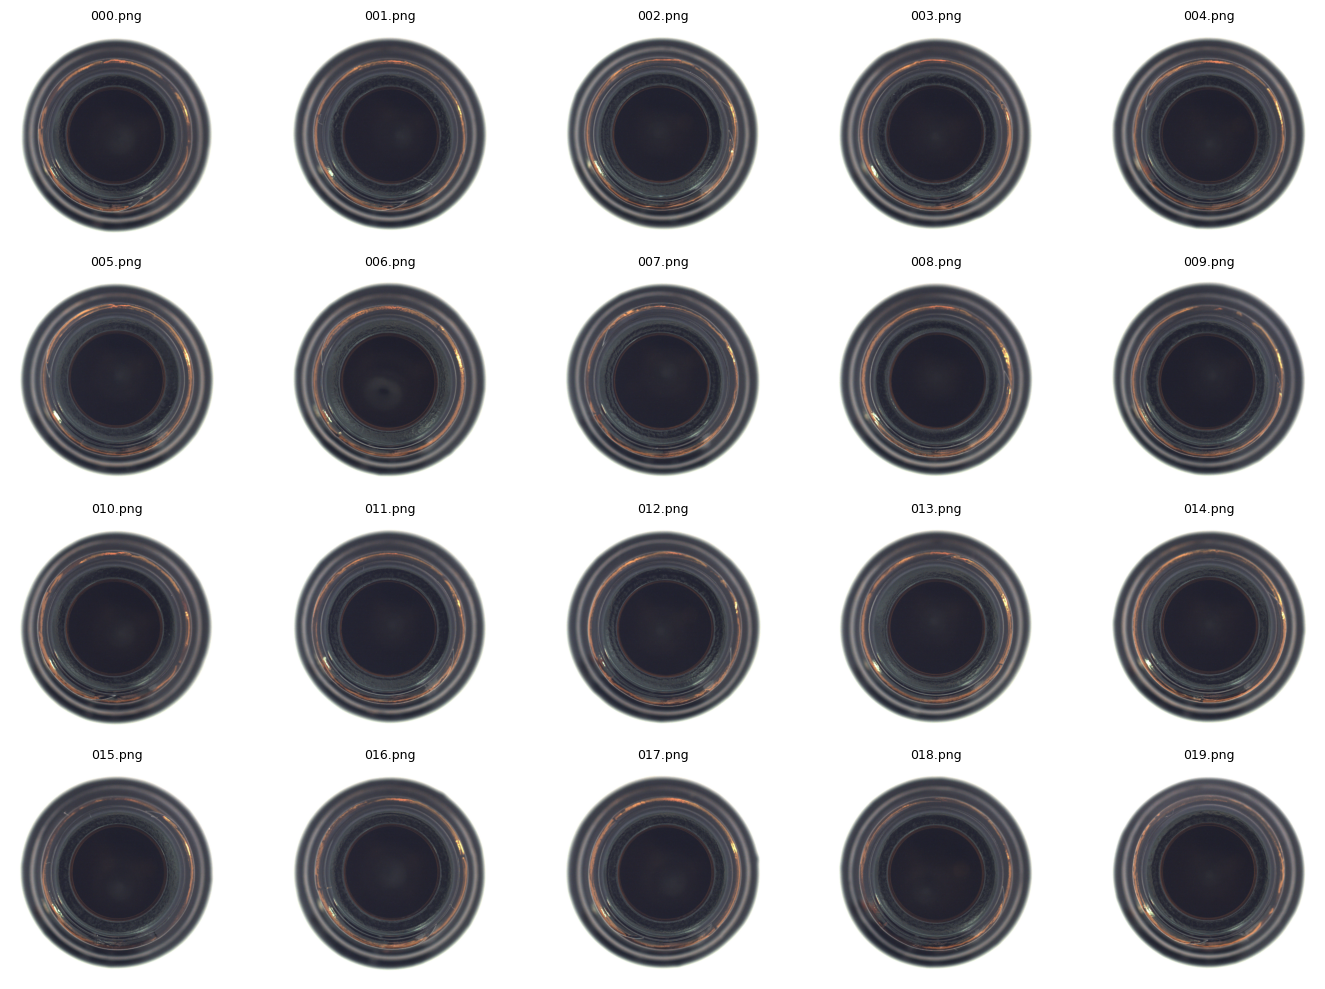

In [79]:
# Display the 20 normal test images for visual inspection

import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 5, figsize=(14, 10))

for ax, path in zip(axes.flat, good_test_paths):
    image = Image.open(path).convert("RGB")
    ax.imshow(image)
    ax.set_title(os.path.basename(path), fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [80]:
# Measure feature variation across normal test images

good_feature_vectors = [
    test_features_all[i].mean(axis=0)
    for i in good_indices
]

good_feature_matrix = np.stack(good_feature_vectors)

feature_distances = np.linalg.norm(
    good_feature_matrix[:, None, :] - good_feature_matrix[None, :, :],
    axis=2
)

upper_triangle = feature_distances[
    np.triu_indices(len(good_indices), k=1)
]

print("Normal images compared:", len(good_indices))
print("Image pairs compared:", len(upper_triangle))
print("Mean feature distance:", upper_triangle.mean())
print("Minimum feature distance:", upper_triangle.min())
print("Maximum feature distance:", upper_triangle.max())

Normal images compared: 20
Image pairs compared: 190
Mean feature distance: 0.1718269
Minimum feature distance: 0.08927164
Maximum feature distance: 0.26630983


### Observation — Normal-Image Feature Variation

The 20 normal test images produced 190 unique image pairs for comparison.
The mean distance between their averaged patch-feature representations was
0.1718, with distances ranging from 0.0893 to 0.2663.

This confirms that the normal images have measurable feature-space differences.
However, these distances alone do not establish the type of variation or
demonstrate robustness to intra-class variation.

## 6. Experiment 4 — Score and Ranking Analysis

**Research question:**  
Does training-set contamination change the ranking of normal and anomalous test images?

**Objective:**  
Compare image-level AUROC and score rankings between the clean and 20% contaminated models.

**Why this matters:**  
AUROC measures how well normal and anomalous images are ranked. Stable AUROC does not necessarily mean individual image rankings remain unchanged.

In [81]:
# Verify test-image categories and score-array alignment

print("Test images:", len(test_images))
print("Clean scores:", len(clean_actual_scores_all))
print("Contaminated scores:", len(contam_actual_scores_all))

print("\nCategory counts:")
from collections import Counter
print(Counter(test_categories))

Test images: 83
Clean scores: 83
Contaminated scores: 83

Category counts:
Counter({'broken_small': 22, 'contamination': 21, 'broken_large': 20, 'good': 20})


In [82]:
# Recalculate image-level AUROC for both models

from sklearn.metrics import roc_auc_score

# good = normal (0); all defect categories = anomalous (1)
test_labels_binary = np.array([
    0 if category == "good" else 1
    for category in test_categories
])

clean_auroc_check = roc_auc_score(
    test_labels_binary, clean_actual_scores_all
)

contam_auroc_check = roc_auc_score(
    test_labels_binary, contam_actual_scores_all
)

print("Clean model AUROC:", clean_auroc_check)
print("20% contaminated model AUROC:", contam_auroc_check)
print("AUROC difference:", contam_auroc_check - clean_auroc_check)

Clean model AUROC: 1.0
20% contaminated model AUROC: 1.0
AUROC difference: 0.0


### Observation — AUROC Verification

The recalculated image-level AUROC was 1.000 for both the clean and 20%
contaminated models, with a difference of 0.000.

Thus, aggregate ranking performance remained unchanged on the 83-image test
set, despite the previously observed changes in nearest-neighbour retrieval
and individual anomaly scores.

### 6.1 Individual Image-Ranking Changes

**Objective:** Compare the relative ranking of test images under the clean and 20% contaminated models.

**Why this is needed:** AUROC remained 1.000 for both models, but individual images may still change their relative ranking.

**Analysis:** Calculate each image's rank under both models and measure the absolute rank change.

In [83]:
# Compare image ranking between clean and contaminated models

clean_ranks = pd.Series(clean_actual_scores_all).rank(method="average")
contam_ranks = pd.Series(contam_actual_scores_all).rank(method="average")

rank_changes = np.abs(
    clean_ranks.to_numpy() - contam_ranks.to_numpy()
)

print("Images compared:", len(rank_changes))
print("Images with changed ranks:", np.sum(rank_changes > 0))
print("Images with unchanged ranks:", np.sum(rank_changes == 0))
print("Mean absolute rank change:", rank_changes.mean())
print("Maximum absolute rank change:", rank_changes.max())


Images compared: 83
Images with changed ranks: 57
Images with unchanged ranks: 26
Mean absolute rank change: 1.6144578313253013
Maximum absolute rank change: 18.0


### Observation — Individual Image-Ranking Changes

Although AUROC remained 1.000 for both models, the relative ranks of 57 out
of 83 test images changed under 20% training-set contamination.

The mean absolute rank change was 1.61 positions, with a maximum change of
18 positions.

This indicates that unchanged aggregate AUROC does not imply identical
image-level rankings. However, all images remained correctly separated by
normal/anomalous class in terms of AUROC.

### 6.2 Normal–Anomaly Score Separation

**Objective:** Verify whether the clean and contaminated models preserve the
separation between normal and anomalous images.

**Why this is needed:** Individual image ranks can change while the overall
normal-versus-anomaly ordering remains perfect.

In [84]:
# Verify normal–anomaly score separation

normal_mask = np.array(test_categories) == "good"
anomaly_mask = ~normal_mask

for model_name, scores in [
    ("Clean model", clean_actual_scores_all),
    ("20% contaminated model", contam_actual_scores_all)
]:
    highest_normal = scores[normal_mask].max()
    lowest_anomaly = scores[anomaly_mask].min()
    separation_margin = lowest_anomaly - highest_normal

    print(f"\n{model_name}")
    print("Highest normal score:", highest_normal)
    print("Lowest anomaly score:", lowest_anomaly)
    print("Separation margin:", separation_margin)
    print("Perfect separation:", separation_margin > 0)


Clean model
Highest normal score: 2.2098770141601562
Lowest anomaly score: 3.249178886413574
Separation margin: 1.039301872253418
Perfect separation: True

20% contaminated model
Highest normal score: 2.438974380493164
Lowest anomaly score: 3.249178886413574
Separation margin: 0.8102045059204102
Perfect separation: True


### Observation — Normal–Anomaly Score Separation

Both models maintained perfect separation between normal and anomalous test
images, consistent with the AUROC of 1.000.

For the clean model, the separation margin was 1.0393. Under 20% training-set
contamination, it decreased to 0.8102 because the highest normal-image score
increased while the lowest anomaly score remained unchanged.

Thus, individual image rankings and the separation margin changed, although
aggregate AUROC remained unchanged.

## Experiment 5 — NN Change vs Score Change

**Research question:**  
Are larger nearest-neighbour changes associated with larger image-level anomaly-score changes?

**Objective:**  
Measure the relationship between the proportion of changed nearest neighbours
and the absolute anomaly-score change across the 83 test images.

In [85]:
from scipy.stats import pearsonr, spearmanr
import numpy as np

# Percentage of nearest neighbours changed for each test image
nn_change_rates = np.array([
    np.mean(changed) * 100 for changed in all_nn_changed
])

# Absolute image-level anomaly-score change
absolute_score_changes = np.abs(
    contam_actual_scores_all - clean_actual_scores_all
)

# Correlation analysis
pearson_r, pearson_p = pearsonr(
    nn_change_rates, absolute_score_changes
)
spearman_r, spearman_p = spearmanr(
    nn_change_rates, absolute_score_changes
)

print("Images analysed:", len(nn_change_rates))
print(f"Mean NN change rate: {nn_change_rates.mean():.2f}%")
print(f"Mean absolute score change: {absolute_score_changes.mean():.6f}")
print(f"Pearson correlation: r = {pearson_r:.4f}, p = {pearson_p:.4f}")
print(f"Spearman correlation: rho = {spearman_r:.4f}, p = {spearman_p:.4f}")

Images analysed: 83
Mean NN change rate: 99.86%
Mean absolute score change: 0.145325
Pearson correlation: r = -0.0503, p = 0.6516
Spearman correlation: rho = -0.0515, p = 0.6436


### Observation — NN Change vs Score Change

The mean nearest-neighbour change rate was **99.86%**, while the mean absolute image-level anomaly-score change was **0.1453**.

Pearson correlation was \(r=-0.0503\) (\(p=0.6516\)), and Spearman correlation was \(\rho=-0.0515\) (\(p=0.6436\)). Both indicate a negligible relationship, with no statistically significant association detected.

Thus, extensive nearest-neighbour replacement did not correspond to larger image-level score changes. However, because the NN change rates were almost identical across images, their limited variability may constrain the strength of this correlation analysis.

In [86]:
import pandas as pd
import numpy as np

# Calculate per-image score and nearest-neighbour changes
score_change = contam_actual_scores_all - clean_actual_scores_all
nn_change_rates = np.array([
    np.mean(changed) * 100 for changed in all_nn_changed
])

# Build comparison table
change_df = pd.DataFrame({
    "Image": test_image_names,
    "Category": test_categories,
    "Clean Score": clean_actual_scores_all,
    "Contaminated Score": contam_actual_scores_all,
    "Score Change": score_change,
    "Absolute Score Change": np.abs(score_change),
    "NN Change (%)": nn_change_rates
})

# Show the 10 images with the largest absolute score changes
top_changes = change_df.sort_values(
    "Absolute Score Change", ascending=False
).head(10)

display(top_changes.round(4).reset_index(drop=True))

,Image,Category,Clean Score,Contaminated Score,Score Change,Absolute Score Change,NN Change (%)
0,007.png,contamination,12.1524,10.4689,-1.6835,1.6835,99.8724
1,021.png,broken_small,7.9816,6.7277,-1.2539,1.2539,99.8724
2,018.png,broken_large,7.9248,7.0922,-0.8325,0.8325,99.8724
3,017.png,contamination,8.6716,7.8866,-0.7850,0.7850,99.7449
4,018.png,contamination,9.8009,9.1041,-0.6968,0.6968,99.8724
5,000.png,contamination,6.3257,5.8453,-0.4804,0.4804,99.7449
6,004.png,broken_small,9.9216,9.4471,-0.4746,0.4746,99.8724
7,017.png,broken_small,9.8644,9.5205,-0.3439,0.3439,99.8724
8,020.png,broken_small,8.7770,8.4504,-0.3266,0.3266,99.8724
9,010.png,broken_large,7.8211,7.5037,-0.3174,0.3174,99.8724


### Observation — Images with the Largest Score Changes

The 10 images with the largest absolute anomaly-score changes were all anomalous samples. Their scores decreased under 20% training-set contamination, with the largest decrease being **1.6835** for a `contamination` image.

Despite these differences in score magnitude, their nearest-neighbour change rates remained between **99.7449% and 99.8724%**. This supports the observation that extensive nearest-neighbour replacement does not necessarily produce proportionally large score changes.

The results suggest that the effect of contamination depends not only on how many nearest neighbours change, but also on the distances of the replacement neighbours. However, this table alone does not establish the precise cause of each score change.

### Experiment 5B — Images with the Largest Score Increases

**Research question:**
Which test images show the largest increases in anomaly scores under 20% training-set contamination?

**Objective:**
Identify the images with the largest positive score changes and compare their categories and nearest-neighbour change rates.

**Why this matters:**
Examining score increases alongside score decreases helps determine whether contamination affects individual test images in a consistent direction or produces mixed responses.&#x20;


In [87]:
# Show the 10 images with the largest score increases
top_increases = (
    change_df[change_df["Score Change"] > 0]
    .sort_values("Score Change", ascending=False)
    .head(10)
)

display(top_increases.round(4).reset_index(drop=True))

,Image,Category,Clean Score,Contaminated Score,Score Change,Absolute Score Change,NN Change (%)
0,015.png,contamination,6.5870,6.8258,0.2389,0.2389,99.7449
1,001.png,good,2.2099,2.4390,0.2291,0.2291,99.8724
2,016.png,broken_small,6.6514,6.7976,0.1462,0.1462,99.8724
3,014.png,contamination,4.5921,4.7373,0.1452,0.1452,99.8724
4,019.png,contamination,3.7940,3.9288,0.1347,0.1347,99.8724
5,011.png,contamination,4.8378,4.9213,0.0835,0.0835,99.8724
6,010.png,good,1.3630,1.4446,0.0816,0.0816,99.8724
7,009.png,broken_large,7.3146,7.3606,0.0460,0.0460,99.8724
8,012.png,good,1.4967,1.5334,0.0368,0.0368,99.7449
9,006.png,broken_large,8.7210,8.7536,0.0327,0.0327,99.8724


### Observation — Images with the Largest Score Increases

The largest positive score change was **0.2389** for a `contamination` image, followed by **0.2291** for a normal (`good`) image. The remaining images also showed positive score changes, but of smaller magnitude.

The top 10 images included normal and anomalous samples, indicating that training-set contamination did not affect every image in the same direction. All 10 images had nearest-neighbour change rates between **99.7449% and 99.8724%**, again showing that the proportion of changed neighbours alone does not explain the magnitude or direction of score changes.

Overall, contamination produced **image-specific score changes**, with both increases and decreases, despite the unchanged aggregate image-level AUROC of 1.000.

## Experiment 6 — Preliminary Intra-Class Variation Analysis

**Research question:**  
How much feature variation exists among normal test images, and how do their anomaly scores change under training-set contamination?

**Objective:**  
Summarize feature-space variation among normal (`good`) test images and compare their anomaly scores between the clean and 20% contaminated models.

**Scope:**  
This is a preliminary analysis of normal-image variation. It does not constitute a controlled evaluation of robustness to intra-class variation.

In [88]:
import numpy as np

normal_indices = [
    i for i, category in enumerate(test_categories)
    if category == "good"
]

normal_clean_scores = clean_actual_scores_all[normal_indices]
normal_contam_scores = contam_actual_scores_all[normal_indices]

normal_score_changes = normal_contam_scores - normal_clean_scores

print("Normal test images:", len(normal_indices))
print(f"Clean model — mean score: {normal_clean_scores.mean():.4f}")
print(f"Clean model — score std:  {normal_clean_scores.std():.4f}")
print(f"Contaminated model — mean score: {normal_contam_scores.mean():.4f}")
print(f"Contaminated model — score std:  {normal_contam_scores.std():.4f}")

print("\nNormal-image score changes:")
print("Increased:", np.sum(normal_score_changes > 1e-6))
print("Decreased:", np.sum(normal_score_changes < -1e-6))
print("Approximately unchanged:", np.sum(np.abs(normal_score_changes) <= 1e-6))
print(f"Mean score change: {normal_score_changes.mean():.6f}")

Normal test images: 20
Clean model — mean score: 1.4089
Clean model — score std:  0.2951
Contaminated model — mean score: 1.4071
Contaminated model — score std:  0.3318

Normal-image score changes:
Increased: 7
Decreased: 9
Approximately unchanged: 4
Mean score change: -0.001852


### Observation — Normal-Image Score Stability

Across the 20 normal test images, the mean anomaly score decreased slightly from **1.4089** for the clean model to **1.4071** for the 20% contaminated model. The mean change was only **−0.001852**.

However, individual responses differed: scores increased for 7 images, decreased for 9, and remained approximately unchanged for 4. The score standard deviation also increased from **0.2951** to **0.3318**.

These findings indicate that a nearly unchanged average score can conceal image-level variation. This is preliminary evidence of differing score responses among normal images, not proof of robustness to intra-class variation.

# Consolidated Experimental Findings
## PatchCore on MVTec AD — Bottle Category

### 1. Experimental Setup

The study investigates how synthetic training-set contamination affects PatchCore, an unsupervised industrial visual anomaly detection method.

- **Dataset:** MVTec AD, Bottle category
- **Model:** PatchCore with WideResNet50
- **Clean training set:** 209 normal images
- **Contamination levels:** 0%, 5%, 10%, and 20%
- **Test set:** 83 images, kept unchanged across experiments
- **Contamination-Level Definition:** The contamination levels were defined relative to the original 209-image clean training set. Accordingly, 10, 21, and 41 contaminated images were added at the nominal 5%, 10%, and 20% levels, resulting in final training sets of 219, 230, and 250 images, respectively. The actual contaminated-image fractions of these final sets were approximately 4.57%, 9.13%, and 16.40%.
- **Evaluation:** Image-level and pixel-level performance, memory-bank composition, nearest-neighbour retrieval, image-level scores and rankings.

### 2. Aggregate Performance

| Training contamination | Instance AUROC | Memory-bank size |
|---|---:|---:|
| 0% | 1.000 | 67.11 MB |
| 5% | 1.000 | 70.32 MB |
| 10% | 1.000 | 73.86 MB |
| 20% | 1.000 | 80.28 MB |

Image-level AUROC remained 1.000 at every contamination level. Pixel-level metrics changed only slightly.

**Finding:** Aggregate detection performance remained stable on this test set. However, this alone does not establish that the model's internal retrieval behaviour or individual predictions remained unchanged.

### 3. Memory-Bank Composition

At 20% training-set contamination:

- Total memory vectors increased from **16,385 to 19,600**.
- The contaminated memory bank contained **16,523 clean-source vectors (84.30%)** and **3,077 contaminated-source vectors (15.70%)**.
- All 41 contaminated training images contributed vectors.
- Only 7,743 clean-source vectors were shared between the clean and contaminated memory banks, corresponding to approximately **47.3% of the clean memory bank**.

**Finding:** Contamination affected both the inclusion of contaminated features and the selection of clean features in the memory bank. The changes therefore extended beyond the direct addition of contaminated examples.

### 4. Nearest-Neighbour Retrieval

Across 83 test images and 65,072 test patches:

- **64,978 patches (99.86%)** changed their nearest neighbour.
- Of the changed neighbours, **87.36%** were clean-source vectors and **12.64%** were contaminated-source vectors.
- Nearest-neighbour distances increased for 38.52% of patches and decreased for 47.02%; 14.45% remained unchanged.

**Finding:** The contaminated model retrieved substantially different reference features, even though aggregate AUROC remained unchanged.

### 5. Image-Level Scores and Rankings

The score calculations were verified against PatchCore's actual prediction pipeline across all 83 test images.

- Both models achieved image-level AUROC of **1.000**.
- The relative ranks of **57 out of 83 images** changed.
- Mean absolute rank change was **1.61 positions**, with a maximum change of 18 positions.
- The normal–anomaly separation margin decreased from **1.0393** to **0.8102**.

The mean absolute score change across all test images was **0.1453**. Some scores increased, while others decreased.

**Finding:** Unchanged aggregate AUROC did not imply identical image-level scores or rankings. The separation between normal and anomalous scores also narrowed, although perfect separation was retained on this test set.

### 6. Relationship Between Retrieval and Score Changes

The correlation between nearest-neighbour change rate and absolute image-level score change was negligible:

- Pearson correlation: \(r=-0.0503\), \(p=0.6516\)
- Spearman correlation: \(\rho=-0.0515\), \(p=0.6436\)

Nearly all images had a nearest-neighbour change rate close to 100%, leaving little variation for correlation analysis.

**Finding:** This analysis did not detect a meaningful association between the proportion of changed neighbours and the magnitude of score changes. It does not establish that retrieval changes are causally unrelated to score changes.

### 7. Preliminary Normal-Image Variation

Among the 20 normal test images:

- Mean anomaly score changed from **1.4089 to 1.4071**.
- Seven scores increased, nine decreased, and four remained approximately unchanged.
- Score standard deviation increased from **0.2951 to 0.3318**.
- Mean pairwise distance between normal-image mean feature vectors was **0.1718** across 190 image pairs.

**Finding:** The average normal-image score was stable, but individual scores varied. This is preliminary evidence of differing responses among normal images; it is not a controlled demonstration of robustness to intra-class variation.

### 8. Overall Research Interpretation

The experiments reveal a distinction between **aggregate detection performance** and **the internal retrieval and image-level scoring behaviour** of PatchCore.

Under the tested synthetic contamination conditions, PatchCore retained perfect image-level AUROC on the fixed Bottle test set while its memory-bank composition, nearest-neighbour assignments, individual image rankings, and score-separation margin changed.

The results support further investigation of how memory-bank construction and nearest-neighbour retrieval influence unsupervised normality modelling. They do not establish that contamination always improves or degrades anomaly detection, nor do they establish generalisation to other categories, datasets, or contamination types.

### 9. Limitations to State in the Manuscript

1. The main experiments use one object category and one fixed test set.
2. Contamination levels are synthetic; conclusions may not transfer directly to real industrial contamination.
3. Perfect AUROC on this test set does not establish general robustness.
4. The correlation analysis is constrained by the very small variation in nearest-neighbour change rates.
5. The normal-image feature-distance analysis is preliminary and does not isolate intra-class variation experimentally.
6. The observed associations do not, by themselves, establish causality.

### 10. Proposed Core Contribution

This study provides an empirical analysis of how training-set contamination changes PatchCore's memory-bank composition and nearest-neighbour retrieval while aggregate image-level detection performance remains unchanged on the evaluated test set.

The central contribution is the demonstration that **stable aggregate metrics can conceal substantial changes in the internal reference structure and individual prediction behaviour of an unsupervised anomaly detection model**.

# Multi-Level Contamination Mechanism Analysis (Clean, 5%, 10%, 20%)

This section extends the existing PatchCore mechanism analysis across four training conditions: clean, 5%, 10%, and 20% contamination. It reuses the existing experiment artifacts and keeps the test set fixed.

The analysis examines how contamination level relates to:
1. Memory-bank size and reference-vector overlap.
2. Nearest-neighbour assignments across the four models.
3. Anomaly-score and ranking changes across test images.
4. The relationship between retrieval changes and score changes.
5. Evidence and limitations concerning intra-class variation.

Previously completed experiments will not be repeated unless verification identifies a specific gap. All conclusions will be based on observed outputs; aggregate metric stability will not be treated as proof that the underlying model behaviour is unchanged.

In [89]:
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/"
    "Semester 1/Machine Learning/IAD_PROJECT"
)

if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError(
        f"Project folder not found: {PROJECT_ROOT}. "
        "Check that Google Drive is mounted."
    )

print("Project root verified:", PROJECT_ROOT)

print("\nFolders containing PatchCore artifacts:")
found = 0

for path in sorted(PROJECT_ROOT.rglob("*")):
    if not path.is_dir():
        continue

    artifact_names = {
        p.name for p in path.iterdir() if p.is_file()
    }

    relevant = (
        "nnscorer_search_index.faiss" in artifact_names
        or "patchcore_params.pkl" in artifact_names
        or "results.csv" in artifact_names
    )

    if relevant:
        print(f"\nFolder: {path.relative_to(PROJECT_ROOT)}")
        for name in sorted(artifact_names):
            if name in {
                "nnscorer_search_index.faiss",
                "patchcore_params.pkl",
                "results.csv",
                "experiment_config.json",
            }:
                print(f"  {name}")
        found += 1

print(f"\nTotal matching folders: {found}")

Project root verified: /content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT

Folders containing PatchCore artifacts:

Folder: Experiments/PatchCore/bottle/10_percent
  results.csv

Folder: Experiments/PatchCore/bottle/10_percent/models/mvtec_bottle
  nnscorer_search_index.faiss
  patchcore_params.pkl

Folder: Experiments/PatchCore/bottle/20_percent
  results.csv

Folder: Experiments/PatchCore/bottle/20_percent/models/mvtec_bottle
  nnscorer_search_index.faiss
  patchcore_params.pkl

Folder: Experiments/PatchCore/bottle/5_percent
  results.csv

Folder: Experiments/PatchCore/bottle/5_percent/models/mvtec_bottle
  nnscorer_search_index.faiss
  patchcore_params.pkl

Folder: Experiments/PatchCore/bottle/PatchCore/clean_baseline
  results.csv

Folder: Experiments/PatchCore/bottle/PatchCore/clean_baseline/models/mvtec_bottle
  nnscorer_search_index.faiss
  patchcore_params.pkl

Folder: Experiments/PatchCore/bottle/PatchCore/clean_baseline_0
  experiment_c

In [90]:
from pathlib import Path
import faiss

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/"
    "Semester 1/Machine Learning/IAD_PROJECT"
)

EXPERIMENT_ROOT = PROJECT_ROOT / "Experiments/PatchCore/bottle"

conditions = {
    "Clean": EXPERIMENT_ROOT / "PatchCore/clean_baseline",
    "5%": EXPERIMENT_ROOT / "5_percent",
    "10%": EXPERIMENT_ROOT / "10_percent",
    "20%": EXPERIMENT_ROOT / "20_percent",
}

memory_bank_info = {}

print("MULTI-LEVEL MEMORY-BANK SUMMARY")
print("=" * 75)

for condition, folder in conditions.items():
    index_path = folder / "models/mvtec_bottle/nnscorer_search_index.faiss"

    if not index_path.is_file():
        raise FileNotFoundError(f"Index not found: {index_path}")

    index = faiss.read_index(str(index_path))

    info = {
        "index_path": index_path,
        "vectors": index.ntotal,
        "dimensions": index.d,
        "size_bytes": index_path.stat().st_size,
        "index_type": type(index).__name__,
    }
    memory_bank_info[condition] = info

    print(f"\nCondition: {condition}")
    print(f"  Vectors: {info['vectors']:,}")
    print(f"  Feature dimensions: {info['dimensions']}")
    print(f"  Index type: {info['index_type']}")
    print(f"  File size: {info['size_bytes']:,} bytes "
          f"({info['size_bytes'] / (1024**2):.2f} MiB)")

print("\nInspection complete. No files were changed.")

MULTI-LEVEL MEMORY-BANK SUMMARY

Condition: Clean
  Vectors: 16,385
  Feature dimensions: 1024
  Index type: IndexFlatL2
  File size: 67,113,005 bytes (64.00 MiB)

Condition: 5%
  Vectors: 17,169
  Feature dimensions: 1024
  Index type: IndexFlatL2
  File size: 70,324,269 bytes (67.07 MiB)

Condition: 10%
  Vectors: 18,032
  Feature dimensions: 1024
  Index type: IndexFlatL2
  File size: 73,859,117 bytes (70.44 MiB)

Condition: 20%
  Vectors: 19,600
  Feature dimensions: 1024
  Index type: IndexFlatL2
  File size: 80,281,645 bytes (76.56 MiB)

Inspection complete. No files were changed.


### 2. Pairwise Memory-Bank Overlap

**Purpose:** Measure the number and percentage of exact feature vectors shared between each pair of contamination conditions. This identifies reference-bank changes but does not establish vector provenance or semantic similarity.

In [91]:
import hashlib
from itertools import combinations
import faiss

# Load and fingerprint the saved vectors in each memory bank.
bank_fingerprints = {}

for condition, folder in conditions.items():
    index_path = folder / "models/mvtec_bottle/nnscorer_search_index.faiss"
    index = faiss.read_index(str(index_path))

    vectors = index.reconstruct_n(0, index.ntotal)

    fingerprints = {
        hashlib.blake2b(row.tobytes(), digest_size=16).hexdigest()
        for row in vectors
    }

    bank_fingerprints[condition] = fingerprints

    print(
        f"{condition}: {len(fingerprints):,} unique exact vectors "
        f"out of {index.ntotal:,}"
    )

# Compare every pair of conditions.
print("\nPAIRWISE EXACT-VECTOR OVERLAP")
print("=" * 85)

for condition_a, condition_b in combinations(bank_fingerprints, 2):
    vectors_a = bank_fingerprints[condition_a]
    vectors_b = bank_fingerprints[condition_b]

    shared = len(vectors_a & vectors_b)
    pct_a = 100 * shared / len(vectors_a)
    pct_b = 100 * shared / len(vectors_b)

    print(
        f"{condition_a} vs {condition_b}: "
        f"shared={shared:,} | "
        f"{condition_a} shared={pct_a:.2f}% | "
        f"{condition_b} shared={pct_b:.2f}%"
    )


Clean: 16,385 unique exact vectors out of 16,385
5%: 17,169 unique exact vectors out of 17,169
10%: 18,032 unique exact vectors out of 18,032
20%: 19,600 unique exact vectors out of 19,600

PAIRWISE EXACT-VECTOR OVERLAP
Clean vs 5%: shared=7,941 | Clean shared=48.47% | 5% shared=46.25%
Clean vs 10%: shared=8,014 | Clean shared=48.91% | 10% shared=44.44%
Clean vs 20%: shared=7,708 | Clean shared=47.04% | 20% shared=39.33%
5% vs 10%: shared=8,399 | 5% shared=48.92% | 10% shared=46.58%
5% vs 20%: shared=8,237 | 5% shared=47.98% | 20% shared=42.03%
10% vs 20%: shared=8,875 | 10% shared=49.22% | 20% shared=45.28%


###**Observation**

All four memory banks contain unique exact vectors with no duplicate fingerprints. Pairwise exact-vector overlap is roughly 39–49% when expressed relative to each bank, and the percentage of the larger bank shared with the clean bank decreases as contamination increases: 46.25% at 5%, 44.44% at 10%, and 39.33% at 20%.

This supports the finding that the saved reference banks differ substantially across conditions. Exact overlap alone cannot identify whether a vector originated from a clean or contaminated training image.

### 3. Verify Existing Test-Feature Artifacts

**Purpose:** Identify whether test-patch features or nearest-neighbour results from the earlier mechanism analysis are already available in the current notebook session. Reuse existing data where possible to avoid repeating feature extraction.

In [92]:
# Inspect existing notebook variables only; no files are changed.
keywords = ("test", "feature", "embedding", "neighbor", "neighbour", "score", "patch")

matches = [
    name for name in globals()
    if any(keyword in name.lower() for keyword in keywords)
    and not name.startswith("_")
]

print("Potentially reusable variables:")
for name in sorted(matches):
    value = globals()[name]
    shape = getattr(value, "shape", None)
    print(f"{name}: type={type(value).__name__}, shape={shape}")

Potentially reusable variables:
NearestNeighbors: type=ABCMeta, shape=None
PatchCore: type=type, shape=None
TEST_DIR: type=str, shape=None
TEST_IMAGE: type=str, shape=None
absolute_score_changes: type=ndarray, shape=(83,)
actual_score_check: type=float, shape=None
actual_scores: type=list, shape=None
changed_patches: type=int64, shape=()
clean_actual_scores_all: type=ndarray, shape=(83,)
clean_image_score: type=float32, shape=()
clean_image_scores: type=ndarray, shape=(83,)
clean_manual_scores_all: type=ndarray, shape=(83,)
clean_scores: type=list, shape=None
clean_training_features: type=ndarray, shape=(163856, 1024)
contam_actual_scores: type=list, shape=None
contam_actual_scores_all: type=ndarray, shape=(83,)
contam_image_score: type=float32, shape=()
contam_image_scores: type=ndarray, shape=(83,)
contam_manual_scores_all: type=ndarray, shape=(83,)
contam_scores: type=list, shape=None
feature_distances: type=ndarray, shape=(20, 20)
features: type=ndarray, shape=(784, 1024)
good_clea

### 4. Test-Feature Compatibility Check

**Purpose:** Verify the structure and dimensionality of the existing test features, then run a small nearest-neighbour query against each saved memory bank. This checks compatibility before scaling the analysis to all 83 test images.

In [93]:
import numpy as np
import faiss

print("test_features_all type:", type(test_features_all).__name__)
print("Number of entries:", len(test_features_all))

first_features = np.asarray(test_features_all[0], dtype=np.float32)

print("First entry shape:", first_features.shape)
print("First entry dtype:", first_features.dtype)

if first_features.ndim != 2:
    raise ValueError(
        f"Expected a 2D feature matrix, got shape {first_features.shape}"
    )

print("\nSINGLE-IMAGE NEAREST-NEIGHBOUR CHECK")
print("=" * 70)

for condition, folder in conditions.items():
    index_path = folder / "models/mvtec_bottle/nnscorer_search_index.faiss"
    index = faiss.read_index(str(index_path))

    if first_features.shape[1] != index.d:
        raise ValueError(
            f"{condition}: feature dimension {first_features.shape[1]} "
            f"does not match index dimension {index.d}"
        )

    distances, indices = index.search(first_features, 1)

    print(
        f"{condition}: "
        f"queries={len(first_features):,}, "
        f"mean squared L2 distance={distances.mean():.6f}, "
        f"matched vectors={len(np.unique(indices)):,}"
    )

test_features_all type: list
Number of entries: 83
First entry shape: (784, 1024)
First entry dtype: float32

SINGLE-IMAGE NEAREST-NEIGHBOUR CHECK
Clean: queries=784, mean squared L2 distance=0.631063, matched vectors=674
5%: queries=784, mean squared L2 distance=0.631386, matched vectors=664
10%: queries=784, mean squared L2 distance=0.623037, matched vectors=674
20%: queries=784, mean squared L2 distance=0.623429, matched vectors=684


### **Observation**
The saved indexes accept the existing test features: the first test image has 784 patches of 1,024 dimensions, matching all four index dimensions. Its mean nearest-neighbour squared L2 distance varies slightly across conditions, from 0.623037 at 10% to 0.631386 at 5%.

This is only a compatibility check on one image. It does not yet tell us whether retrieval changes are consistent across the full test set.

Next: Full 83-image retrieval comparison

### 5. Multi-Level Nearest-Neighbour Analysis

**Purpose:** Compare nearest-neighbour assignments for all 83 test images across Clean, 5%, 10%, and 20% memory banks. Vector fingerprints will be used instead of FAISS row IDs because row IDs are not comparable across different indexes.

In [94]:
import numpy as np
import faiss
import hashlib

# Build exact fingerprints for each saved bank's vectors.
bank_vector_fingerprints = {}
retrieval_results = {}

for condition, folder in conditions.items():
    index_path = folder / "models/mvtec_bottle/nnscorer_search_index.faiss"
    index = faiss.read_index(str(index_path))
    bank_vectors = index.reconstruct_n(0, index.ntotal)

    bank_vector_fingerprints[condition] = [
        hashlib.blake2b(row.tobytes(), digest_size=16).hexdigest()
        for row in bank_vectors
    ]

    all_distances = []
    all_neighbour_fingerprints = []

    for image_features in test_features_all:
        image_features = np.asarray(image_features, dtype=np.float32)
        distances, indices = index.search(image_features, 1)

        all_distances.append(distances[:, 0])
        all_neighbour_fingerprints.append(
            np.asarray(bank_vector_fingerprints[condition], dtype=object)[
                indices[:, 0]
            ]
        )

    retrieval_results[condition] = {
        "distances": all_distances,
        "neighbours": all_neighbour_fingerprints,
    }

# Summarize each condition and compare its retrievals against Clean.
clean_neighbours = retrieval_results["Clean"]["neighbours"]

print("FULL TEST-SET NEAREST-NEIGHBOUR COMPARISON")
print("=" * 80)

for condition in conditions:
    distances = np.concatenate(retrieval_results[condition]["distances"])
    neighbours = retrieval_results[condition]["neighbours"]

    if condition == "Clean":
        changed = 0
    else:
        changed = sum(
            np.count_nonzero(current != baseline)
            for current, baseline in zip(neighbours, clean_neighbours)
        )

    total_patches = sum(len(x) for x in neighbours)

    print(f"\n{condition}")
    print(f"  Test patches: {total_patches:,}")
    print(f"  Mean squared L2 distance: {distances.mean():.6f}")
    print(f"  Median squared L2 distance: {np.median(distances):.6f}")
    print(f"  Patches with changed nearest vector vs Clean: {changed:,}")
    print(f"  Retrieval change rate vs Clean: {100 * changed / total_patches:.2f}%")

print("\nComparison complete; no files were modified.")

FULL TEST-SET NEAREST-NEIGHBOUR COMPARISON

Clean
  Test patches: 65,072
  Mean squared L2 distance: 1.045363
  Median squared L2 distance: 0.666630
  Patches with changed nearest vector vs Clean: 0
  Retrieval change rate vs Clean: 0.00%

5%
  Test patches: 65,072
  Mean squared L2 distance: 1.040434
  Median squared L2 distance: 0.658977
  Patches with changed nearest vector vs Clean: 54,455
  Retrieval change rate vs Clean: 83.68%

10%
  Test patches: 65,072
  Mean squared L2 distance: 1.035822
  Median squared L2 distance: 0.656378
  Patches with changed nearest vector vs Clean: 54,930
  Retrieval change rate vs Clean: 84.41%

20%
  Test patches: 65,072
  Mean squared L2 distance: 1.028050
  Median squared L2 distance: 0.651869
  Patches with changed nearest vector vs Clean: 55,749
  Retrieval change rate vs Clean: 85.67%

Comparison complete; no files were modified.


In [95]:

# Check whether any fingerprints map to conflicting source labels

from collections import defaultdict

fingerprint_labels = defaultdict(set)

for fp, label in zip(bank_vector_fingerprints["20%"], matched_labels):
    fingerprint_labels[fp].add(str(label))

conflicts = {
    fp: labels
    for fp, labels in fingerprint_labels.items()
    if len(labels) > 1
}

print("Memory vectors:", len(matched_labels))
print("Unique fingerprints:", len(fingerprint_labels))
print("Fingerprints with conflicting source labels:", len(conflicts))
print("Clean labels:", np.sum(matched_labels == "clean"))
print("Contaminated labels:", np.sum(matched_labels == "contaminated"))


Memory vectors: 19600
Unique fingerprints: 19600
Fingerprints with conflicting source labels: 0
Clean labels: 16523
Contaminated labels: 3077


In [96]:

# Section 5.2 — Contaminated-Neighbour Verification
# Compare clean vs 20% memory-bank retrievals for all test patches.

import numpy as np

clean_neighbours = retrieval_results["Clean"]["neighbours"]
contam_neighbours = retrieval_results["20%"]["neighbours"]

# Map each 20% memory fingerprint to its source label.
source_label_by_fingerprint = dict(
    zip(bank_vector_fingerprints["20%"], matched_labels)
)

total_patches = 0
changed_patches = 0
contaminated_retrievals = 0
changed_to_contaminated = 0
changed_to_clean = 0

for clean_fp, contam_fp in zip(clean_neighbours, contam_neighbours):
    clean_fp = np.asarray(clean_fp, dtype=object)
    contam_fp = np.asarray(contam_fp, dtype=object)

    changed = clean_fp != contam_fp
    labels = np.array([
        source_label_by_fingerprint[fp]
        for fp in contam_fp
    ])

    total_patches += len(changed)
    changed_patches += int(changed.sum())
    contaminated_retrievals += int(np.sum(labels == "contaminated"))
    changed_to_contaminated += int(
        np.sum(changed & (labels == "contaminated"))
    )
    changed_to_clean += int(
        np.sum(changed & (labels == "clean"))
    )

print("Total test patches:", total_patches)
print("Changed nearest neighbours:", changed_patches)
print(f"Retrieval change rate: {100 * changed_patches / total_patches:.2f}%")
print("\nAll contaminated-source retrievals:", contaminated_retrievals)
print(f"Percentage of all patches: {100 * contaminated_retrievals / total_patches:.2f}%")
print("\nChanged → contaminated source:", changed_to_contaminated)
print("Changed → clean source:", changed_to_clean)
print(
    f"Changed retrievals → contaminated: "
    f"{100 * changed_to_contaminated / changed_patches:.2f}%"
    if changed_patches else "No changed retrievals"
)


Total test patches: 65072
Changed nearest neighbours: 55749
Retrieval change rate: 85.67%

All contaminated-source retrievals: 8300
Percentage of all patches: 12.76%

Changed → contaminated source: 8291
Changed → clean source: 47458
Changed retrievals → contaminated: 14.87%


### **Observation**
Nearest-neighbour assignments change substantially across the test set: compared with Clean, 83.68% of patches at 5%, 84.41% at 10%, and 85.67% at 20% contamination retrieve a different exact memory-bank vector.

Meanwhile, mean and median nearest-neighbour distances decrease as contamination increases. This suggests that the contaminated-condition banks provide different—and, on average, closer under this distance measure—reference vectors. It does not establish that these matches are more semantically appropriate or that anomaly detection has improved.

Next: Check the existing scoring function before comparing scores

### 6. Verify Multi-Level Anomaly-Score Availability

**Purpose:** Inspect the existing model-loading function and available score arrays before computing new predictions. This avoids duplicating the completed Clean-versus-20% score analysis and ensures the 5% and 10% conditions use the established PatchCore inference pipeline.

In [97]:
import inspect
import numpy as np

print("Existing score arrays:")
for name in [
    "clean_actual_scores_all",
    "contam_actual_scores_all",
    "clean_image_scores",
    "contam_image_scores",
    "test_labels_binary",
]:
    value = globals().get(name)
    if value is None:
        print(f"{name}: not available")
    else:
        arr = np.asarray(value)
        print(f"{name}: shape={arr.shape}, dtype={arr.dtype}")

print("\nExisting model-loading function:")
print("Signature:", inspect.signature(load_patchcore))

try:
    print(inspect.getsource(load_patchcore))
except (OSError, TypeError):
    print("Function source is not available through inspect in this session.")

Existing score arrays:
clean_actual_scores_all: shape=(83,), dtype=float64
contam_actual_scores_all: shape=(83,), dtype=float64
clean_image_scores: shape=(83,), dtype=float32
contam_image_scores: shape=(83,), dtype=float32
test_labels_binary: shape=(83,), dtype=int64

Existing model-loading function:
Signature: (model_path)
def load_patchcore(model_path):
    model = PatchCore(device)
    nn_method = FaissNN(on_gpu=False, num_workers=4)
    # Creates the FAISS nearest-neighbour search system that PatchCore uses to find similar feature vectors.

    model.load_from_path(
        load_path=model_path,
        device=device,
        nn_method=nn_method
    )

    return model



### 7. Inspect the Existing PatchCore Prediction Pipeline

**Purpose:** Identify how the current notebook loads a trained PatchCore model and obtains image-level anomaly scores. This ensures that the 5% and 10% models are evaluated consistently with the previously verified Clean and 20% results.

In [98]:
import inspect

print("Existing model-related variables:")
for name in sorted(globals()):
    value = globals()[name]
    if name.lower() in {"model", "clean_model", "contam_model",
                        "patchcore_model", "loaded_model"}:
        print(f"\n{name}: {type(value).__name__}")
        for method_name in ("predict", "evaluate", "load_from_path"):
            method = getattr(value, method_name, None)
            if callable(method):
                try:
                    print(f"  {method_name}{inspect.signature(method)}")
                except (TypeError, ValueError):
                    print(f"  {method_name}: available")

print("\nExisting scoring-related function definitions:")
for name, value in sorted(globals().items()):
    if callable(value) and any(
        word in name.lower() for word in ("score", "predict", "evaluate", "inference")
    ):
        try:
            print(f"{name}{inspect.signature(value)}")
        except (TypeError, ValueError):
            print(name)

Existing model-related variables:

CLEAN_MODEL: str

CONTAM_MODEL: str

clean_model: PatchCore
  predict(data)
  load_from_path(load_path: str, device: torch.device, nn_method: <patchcore.common.FaissNN object at 0x7ef3323a2850>, prepend: str = '') -> None

contam_model: PatchCore
  predict(data)
  load_from_path(load_path: str, device: torch.device, nn_method: <patchcore.common.FaissNN object at 0x7ef3323a2850>, prepend: str = '') -> None

Existing scoring-related function definitions:
roc_auc_score(y_true, y_score, *, average='macro', sample_weight=None, max_fpr=None, multi_class='raise', labels=None)


### 8. Verify PatchCore Prediction Output

**Purpose:** Inspect the prediction output using the existing image tensor to confirm the returned score and anomaly-map structure before extending evaluation to all contamination levels.

In [100]:
# Use the already-loaded tensor instead of the image path.
sample_image = test_image

print("Input type:", type(sample_image).__name__)
print("Input shape:", tuple(sample_image.shape))

prediction_output = clean_model.predict(sample_image)

print("\nPrediction output type:", type(prediction_output).__name__)

if isinstance(prediction_output, dict):
    print("Output keys:", list(prediction_output.keys()))
    for key, value in prediction_output.items():
        print(
            f"{key}: type={type(value).__name__}, "
            f"shape={getattr(value, 'shape', None)}"
        )

elif isinstance(prediction_output, (tuple, list)):
    print("Number of returned items:", len(prediction_output))
    for i, value in enumerate(prediction_output):
        print(
            f"Item {i}: type={type(value).__name__}, "
            f"shape={getattr(value, 'shape', None)}"
        )

else:
    print("Output shape:", getattr(prediction_output, "shape", None))

Input type: Tensor
Input shape: (1, 3, 224, 224)

Prediction output type: tuple
Number of returned items: 2
Item 0: type=list, shape=None
Item 1: type=list, shape=None


### 9. Inspect Prediction Components

**Purpose:** Identify the contents and shapes of the two outputs returned by PatchCore for one test image, without running additional inference or changing model artifacts.

In [101]:
for i, component in enumerate(prediction_output):
    print(f"\nOutput {i}:")
    print("Type:", type(component).__name__)
    print("Length:", len(component))

    if len(component) > 0:
        first_item = component[0]
        print("First item type:", type(first_item).__name__)
        print("First item shape:", getattr(first_item, "shape", None))
        print("First item value preview:")

        if hasattr(first_item, "shape"):
            print(first_item)
        else:
            print(repr(first_item)[:500])


Output 0:
Type: list
Length: 1
First item type: float32
First item shape: ()
First item value preview:
0.9374027

Output 1:
Type: list
Length: 1
First item type: ndarray
First item shape: (224, 224)
First item value preview:
[[0.614465   0.61766696 0.62399054 ... 0.09486832 0.0840032  0.07852456]
 [0.6183114  0.6213489  0.6273462  ... 0.09993176 0.08944174 0.08415265]
 [0.6259173  0.62862766 0.63397604 ... 0.11002588 0.10027977 0.09536662]
 ...
 [0.09436779 0.09822629 0.10585498 ... 0.33979133 0.34768865 0.35167772]
 [0.08409671 0.08824005 0.09643202 ... 0.35089332 0.3590583  0.36318183]
 [0.07891377 0.08320097 0.0916774  ... 0.35649532 0.3647955  0.36898696]]


### 10. Verify Model Paths and Test-Image Inputs

**Purpose:** Confirm the exact saved model paths and test-image input format before loading the 5% and 10% models for consistent score evaluation.

In [102]:
from pathlib import Path

print("Existing model paths:")
print("CLEAN_MODEL:", CLEAN_MODEL)
print("CONTAM_MODEL:", CONTAM_MODEL)

print("\nConfigured experiment model paths:")
for condition, folder in conditions.items():
    model_path = folder / "models/mvtec_bottle"
    print(f"{condition}: {model_path}")
    print("  Exists:", model_path.is_dir())

print("\nTest-image input:")
print("TEST_DIR:", TEST_DIR)
print("Number of test entries:", len(test_images))
print("First test entry:", repr(test_images[0]))
print("TEST_IMAGE:", repr(TEST_IMAGE))

Existing model paths:
CLEAN_MODEL: /content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/PatchCore/clean_baseline/models/mvtec_bottle
CONTAM_MODEL: /content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/20_percent/models/mvtec_bottle

Configured experiment model paths:
Clean: /content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/PatchCore/clean_baseline/models/mvtec_bottle
  Exists: True
5%: /content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/5_percent/models/mvtec_bottle
  Exists: True
10%: /content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/10_percent/models/mvtec_bottle
  Exists: True
20%: /content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machi

### 11. Multi-Level Image-Score Evaluation

**Purpose:** Evaluate all 83 fixed test images using the saved Clean, 5%, 10%, and 20% PatchCore models. Reuse the existing preprocessing pipeline and compare the resulting image-level scores with previously stored Clean and 20% scores for consistency.

In [103]:
import numpy as np
import torch
from PIL import Image
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score

# Load all four saved models using the verified paths.
models = {
    condition: load_patchcore(str(folder / "models/mvtec_bottle"))
    for condition, folder in conditions.items()
}

# Evaluate in the existing test_images order.
multi_level_scores = {condition: [] for condition in conditions}

for image_path in tqdm(test_images, desc="Scoring test images"):
    image = Image.open(image_path).convert("RGB")
    image_tensor = transform_patchcore(image).unsqueeze(0)

    for condition, model in models.items():
        with torch.no_grad():
            prediction, _ = model.predict(image_tensor)

        multi_level_scores[condition].append(float(prediction[0]))

multi_level_scores = {
    condition: np.asarray(scores, dtype=np.float64)
    for condition, scores in multi_level_scores.items()
}

print("TEST-SET SCORE SUMMARY")
print("=" * 70)

for condition, scores in multi_level_scores.items():
    auc = roc_auc_score(test_labels_binary, scores)
    print(
        f"{condition}: n={len(scores)}, "
        f"mean={scores.mean():.6f}, "
        f"std={scores.std():.6f}, "
        f"AUROC={auc:.6f}"
    )

# Validate the reproduced scores against the earlier stored arrays.
print("\nCONSISTENCY CHECK AGAINST EXISTING SCORES")
print("=" * 70)

for condition, existing in [
    ("Clean", clean_actual_scores_all),
    ("20%", contam_actual_scores_all),
]:
    reproduced = multi_level_scores[condition]
    existing = np.asarray(existing, dtype=np.float64)

    if reproduced.shape != existing.shape:
        print(f"{condition}: shape mismatch — {reproduced.shape} vs {existing.shape}")
    else:
        print(
            f"{condition}: max absolute difference="
            f"{np.max(np.abs(reproduced - existing)):.10f}"
        )

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=Wide_ResNet50_2_Weights.IMAGENET1K_V1`. You can also use `weights=Wide_ResNet50_2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Scoring test images:   0%|          | 0/83 [00:00<?, ?it/s]

TEST-SET SCORE SUMMARY
Clean: n=83, mean=5.732446, std=2.877648, AUROC=1.000000
5%: n=83, mean=5.694642, std=2.810186, AUROC=1.000000
10%: n=83, mean=5.670999, std=2.784780, AUROC=1.000000
20%: n=83, mean=5.619413, std=2.759387, AUROC=1.000000

CONSISTENCY CHECK AGAINST EXISTING SCORES
Clean: max absolute difference=0.0000000000
20%: max absolute difference=0.0000000000


**Observation:** All four models achieved an image-level AUROC of 1.000. Mean anomaly scores decreased from 5.7324 (Clean) to 5.6194 (20% contamination), indicating a shift in score magnitude without a change in aggregate AUROC. Further analysis is needed to assess ranking changes and normal–anomaly separation.

### Mean anomaly score comparison across all four contamination levels.

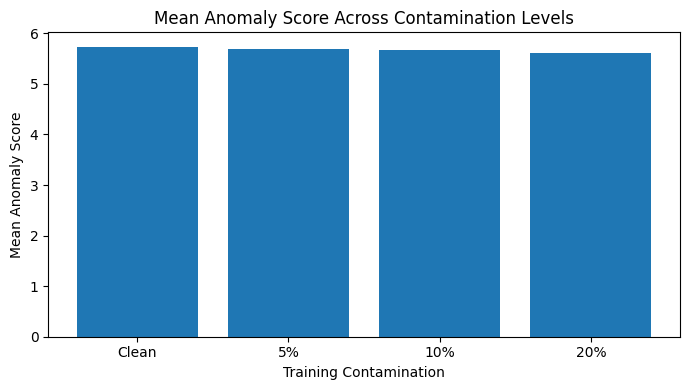

In [104]:
import matplotlib.pyplot as plt
import numpy as np

levels = ["Clean", "5%", "10%", "20%"]
mean_scores = [
    np.mean(multi_level_scores[level])
    for level in levels
]

plt.figure(figsize=(7, 4))
plt.bar(levels, mean_scores)
plt.xlabel("Training Contamination")
plt.ylabel("Mean Anomaly Score")
plt.title("Mean Anomaly Score Across Contamination Levels")
plt.tight_layout()
plt.show()

**Key Findings**
- **Trend:** Mean anomaly score decreased as contamination increased.
- **Clean model:** 5.7324
- **20% contamination:** 5.6194
- **AUROC:** Remained 1.000 for all four models.

**Conclusion:** Contamination slightly shifted the anomaly-score scale, but overall detection performance remained unchanged on the evaluated test set. Lower scores alone do not indicate better or worse performance.

### 12. Score and Ranking Comparison

**Purpose:** Compare score shifts, image ranking changes, and the separation between normal and anomalous test images across all four contamination levels. The same 83 test images and verified labels are used throughout.

In [105]:
import numpy as np
import pandas as pd
from scipy.stats import rankdata

labels = np.asarray(test_labels_binary)
normal_mask = labels == 0
anomaly_mask = labels == 1

# Higher anomaly scores receive higher ranks.
rankings = {
    condition: rankdata(scores)
    for condition, scores in multi_level_scores.items()
}

clean_scores = multi_level_scores["Clean"]
clean_ranks = rankings["Clean"]

rows = []

for condition, scores in multi_level_scores.items():
    ranks = rankings[condition]

    normal_mean = scores[normal_mask].mean()
    anomaly_mean = scores[anomaly_mask].mean()

    rows.append({
        "Condition": condition,
        "Mean score": scores.mean(),
        "Mean score change vs Clean": (scores - clean_scores).mean(),
        "Mean absolute score change": np.abs(scores - clean_scores).mean(),
        "Images with changed rank": int(np.count_nonzero(ranks != clean_ranks)),
        "Mean absolute rank change": np.abs(ranks - clean_ranks).mean(),
        "Normal mean score": normal_mean,
        "Anomaly mean score": anomaly_mean,
        "Separation margin": anomaly_mean - normal_mean,
    })

comparison_df = pd.DataFrame(rows).round(6)
display(comparison_df)

,Condition,Mean score,Mean score change vs Clean,Mean absolute score change,Images with changed rank,Mean absolute rank change,Normal mean score,Anomaly mean score,Separation margin
0,Clean,5.732446,0.000000,0.000000,0,0.000000,1.408911,7.104997,5.696085
1,5%,5.694642,-0.037804,0.093526,50,1.132530,1.411122,7.054489,5.643368
2,10%,5.670999,-0.061447,0.118605,55,1.421687,1.432848,7.016444,5.583595
3,20%,5.619413,-0.113033,0.145325,57,1.614458,1.407059,6.956668,5.549609


**Key Findings**

- **Score change:** Mean absolute score change increased from 0.0935 (5%) to 0.1453 (20%).
- **Ranking change:** At 20% contamination, 57 out of 83 test images changed rank compared with the Clean model.
- **Separation margin:** Decreased from 5.6961 (Clean) to 5.5496 (20%).
- **Normal vs. anomaly scores:** The separation between their mean scores decreased slightly as contamination increased.

**Conclusion:** Although AUROC remained 1.000, individual image scores and rankings changed. This shows that stable overall AUROC does not mean the model's internal predictions remained identical.

### Mean absolute score change and number of images with changed rankings.

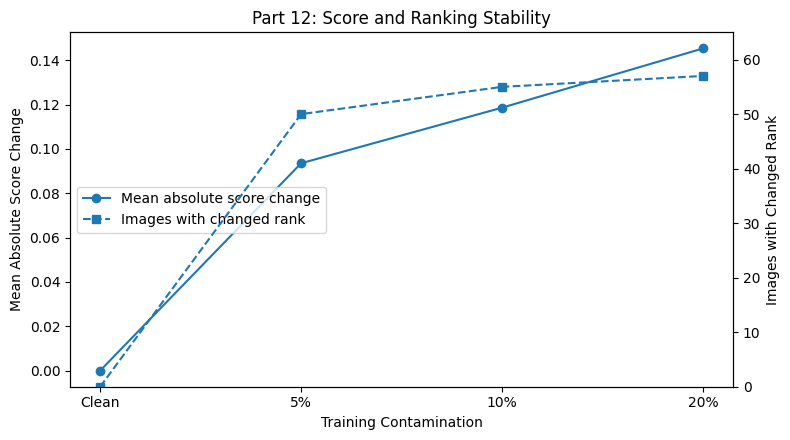

In [106]:
import matplotlib.pyplot as plt

levels = ["Clean", "5%", "10%", "20%"]
score_change = [0.0000, 0.093526, 0.118605, 0.145325]
rank_changed = [0, 50, 55, 57]

fig, ax1 = plt.subplots(figsize=(8, 4.5))

ax1.plot(levels, score_change, marker="o", label="Mean absolute score change")
ax1.set_xlabel("Training Contamination")
ax1.set_ylabel("Mean Absolute Score Change")

ax2 = ax1.twinx()
ax2.plot(levels, rank_changed, marker="s", linestyle="--",
         label="Images with changed rank")
ax2.set_ylabel("Images with Changed Rank")
ax2.set_ylim(0, 65)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="center left")

plt.title("Part 12: Score and Ranking Stability")
plt.tight_layout()
plt.show()

**Key Findings**
- **Score change:** Increased with contamination, reaching 0.1453 at 20%.
- **Ranking change:** 57 of 83 images changed rank at 20% contamination.
- **Overall trend:** Both measures increased as contamination rose.

**Conclusion:** Training-set contamination altered individual image scores and rankings. Despite these changes, AUROC remained 1.000, showing that stable overall detection performance does not guarantee stable individual predictions.

### 13. Retrieval Changes vs. Anomaly-Score Changes

**Purpose:** Examine whether the proportion of test patches with changed nearest neighbours is associated with the magnitude of image-level anomaly-score changes across the four contamination conditions.

In [107]:
import numpy as np
from scipy.stats import pearsonr, spearmanr

clean_scores = multi_level_scores["Clean"]

print("RETRIEVAL CHANGE VS SCORE CHANGE")
print("=" * 65)

for condition in ("5%", "10%", "20%"):
    patch_changes = []
    score_changes = []

    for baseline_neighbours, current_neighbours, baseline_score, current_score in zip(
        retrieval_results["Clean"]["neighbours"],
        retrieval_results[condition]["neighbours"],
        clean_scores,
        multi_level_scores[condition],
    ):
        patch_changes.append(
            np.mean(baseline_neighbours != current_neighbours)
        )
        score_changes.append(abs(current_score - baseline_score))

    patch_changes = np.asarray(patch_changes)
    score_changes = np.asarray(score_changes)

    pearson_r, pearson_p = pearsonr(patch_changes, score_changes)
    spearman_rho, spearman_p = spearmanr(patch_changes, score_changes)

    print(f"\nCondition: {condition}")
    print(f"Mean retrieval change: {patch_changes.mean() * 100:.2f}%")
    print(f"Mean absolute score change: {score_changes.mean():.6f}")
    print(f"Pearson r={pearson_r:.4f}, p={pearson_p:.4f}")
    print(f"Spearman rho={spearman_rho:.4f}, p={spearman_p:.4f}")

RETRIEVAL CHANGE VS SCORE CHANGE

Condition: 5%
Mean retrieval change: 83.68%
Mean absolute score change: 0.093526
Pearson r=-0.0692, p=0.5341
Spearman rho=-0.0025, p=0.9818

Condition: 10%
Mean retrieval change: 84.41%
Mean absolute score change: 0.118605
Pearson r=0.0636, p=0.5679
Spearman rho=0.1232, p=0.2670

Condition: 20%
Mean retrieval change: 85.67%
Mean absolute score change: 0.145325
Pearson r=0.0639, p=0.5662
Spearman rho=0.1013, p=0.3620


**Key Findings**
- **Retrieval change:** Increased from 83.68% (5%) to 85.67% (20%).
- **Score change:** Mean absolute score change increased from 0.0935 to 0.1453.
- **Correlation:** Pearson and Spearman correlations were close to zero across all contamination levels.
- **Statistical significance:** All p-values were above 0.05.

**Conclusion:** Nearest-neighbour retrieval changed substantially, but these changes showed no statistically significant association with image-level score changes. Therefore, retrieval changes alone did not explain the observed score variations.

### Compare retrieval changes with mean absolute score changes across contamination levels.

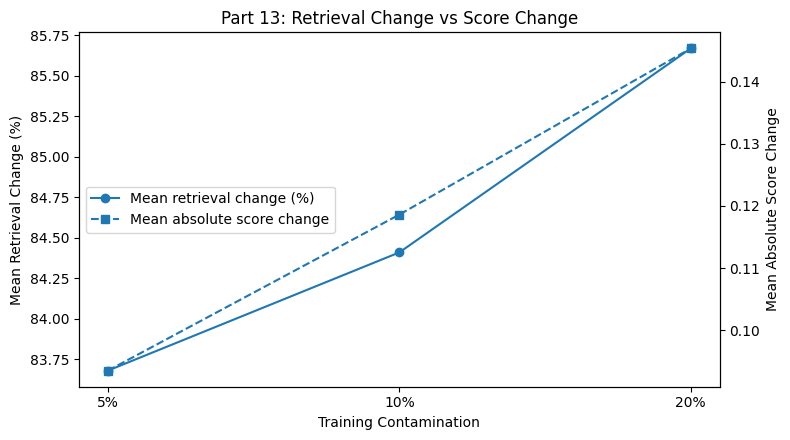

In [108]:
import matplotlib.pyplot as plt

levels = ["5%", "10%", "20%"]
retrieval_change = [83.68, 84.41, 85.67]
score_change = [0.093526, 0.118605, 0.145325]

fig, ax1 = plt.subplots(figsize=(8, 4.5))

ax1.plot(levels, retrieval_change, marker="o",
         label="Mean retrieval change (%)")
ax1.set_xlabel("Training Contamination")
ax1.set_ylabel("Mean Retrieval Change (%)")

ax2 = ax1.twinx()
ax2.plot(levels, score_change, marker="s", linestyle="--",
         label="Mean absolute score change")
ax2.set_ylabel("Mean Absolute Score Change")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="center left")

plt.title("Part 13: Retrieval Change vs Score Change")
plt.tight_layout()
plt.show()

**Key Findings**
- **Retrieval change:** Increased from 83.68% (5%) to 85.67% (20%).
- **Score change:** Increased from 0.0935 to 0.1453.
- **Important result:** Both measures increased, but correlation tests showed no statistically significant association (*p* > 0.05).

**Conclusion:** Greater contamination changed more nearest-neighbour matches and shifted image scores. However, the statistical tests found no meaningful relationship between the two changes. Their simultaneous increase does not establish that retrieval changes caused score changes.

### 14. Consolidated Multi-Level Findings

**Purpose:** Summarize the effects of training-set contamination on PatchCore's memory bank, nearest-neighbour assignments, anomaly scores, and detection performance across the Clean, 5%, 10%, and 20% conditions.

**Key Findings:**

1. **Memory-bank growth:** The memory bank increased from 16,385 vectors in the clean condition to 19,600 at 20% contamination, a 19.62% increase.

2. **Reference-structure changes:** Exact-vector overlap and nearest-neighbour comparisons confirmed substantial differences between memory banks. Relative to Clean, 83.68%, 84.41%, and 85.67% of test patches changed their nearest-neighbour assignment at 5%, 10%, and 20% contamination, respectively.

3. **Stable aggregate detection performance:** All four models achieved an image-level AUROC of 1.000 on the same fixed set of 83 cleanly evaluated test images.

4. **Image-level score and ranking changes:** At 20% contamination, 57 of 83 images changed rank relative to the clean model, and the mean absolute score change was 0.1453. The normal–anomaly separation margin decreased from 5.6961 to 5.5496.

5. **Retrieval changes versus score changes:** The correlation between patch-level retrieval-change rate and image-level absolute score change was negligible at every contamination level; all correlation tests had p-values above 0.05.

**Overall Interpretation:** Training-set contamination changed PatchCore's memory-bank structure, nearest-neighbour assignments, and individual image scores, while image-level AUROC remained unchanged on this test set. These findings show that stable aggregate performance does not necessarily imply stable internal reference structure or identical image-level rankings. The results are limited to the MVTec AD Bottle category, the fixed test set, and the contamination settings evaluated.